# Assessment 2: Machine-learning analysis of bacterial abundance and environmental data

*OCES 5303 – Machine Learning for Ocean Science*

**Student ID:** 21421489

**Data source:** Weekly bacterial abundance and environmental observations (`PIDweekly_env_data.txt`), distributed through the course repository (julianmak): https://raw.githubusercontent.com/julianmak/OCES4303_ML_ocean/refs/heads/main/PIDweekly_env_data.txt

<a id="contents"></a>
## Contents

1. [Introduction and background](#s1)
2. [Data: loading, quality control and sampling](#s2)
3. [Evaluation set-up](#s3)
4. [Baselines](#s4)
5. [Multi-layer perceptrons](#s5)
6. [Autoencoder](#s6)
7. [1D convolutional network](#s7)
8. [RNN, LSTM and GRU](#s8)
9. [Conclusions](#s9)
10. [References](#refs)

-----------------------
# 1. Introduction and background

## 1.1 Bacterial abundance in the coastal ocean

Heterotrophic bacteria are the most numerous organisms in seawater (of order $10^6$ cells mL$^{-1}$ in the surface ocean) and process a large fraction of the organic matter produced by phytoplankton, a pathway known as the microbial loop (Azam et al., 1983). Bacterial abundance at a given time is the net outcome of several competing processes:

* **Substrate supply.** Dissolved organic matter is largely of phytoplankton origin, so chlorophyll (a proxy for phytoplankton biomass) is an obvious candidate predictor; bacterial production has been shown to scale with phytoplankton biomass across aquatic systems (Cole et al., 1988).
* **Temperature**, which sets bacterial growth rates (White et al., 1991) and is therefore expected to impose a seasonal cycle following temperature and insolation.
* **Losses** through grazing and viral lysis, which are not measured in this data set.
* **Physical forcing** in a coastal setting, such as freshwater input (salinity, DIC), tidal state (`MLLW`) and nutrient pulses.

## 1.2 Data set

The file `PIDweekly_env_data.txt` contains one row per weekly sample (julianmak). The columns are listed below. The file does not state units; the units given are those customary for this type of measurement and are an assumption.

| column | meaning | units (assumed) |
|---|---|---|
| `SampleID` | sample label (not used as a feature) | – |
| `YearDay` | days since the start of the record (exceeds 365; the record spans roughly three years) | days |
| `Bacteria_abundance` | bacterial abundance (**target**) | cells mL$^{-1}$ |
| `Projected_Daily_Insolation` | modelled daily solar input, a deterministic function of date | – |
| `Temp` | water temperature | °C |
| `MLLW` | tide height relative to mean lower low water | m |
| `Salinity` | salinity | – |
| `Oxygen_Saturation` | dissolved oxygen saturation | % |
| `pH` | pH | – |
| `DIC` | dissolved inorganic carbon | µmol kg$^{-1}$ |
| `Chlorophyll` | chlorophyll concentration | µg L$^{-1}$ |
| `NH4`, `NO2.NO3`, `PO4`, `SiO4` | ammonium, nitrite + nitrate, phosphate, silicate | nmol or µmol L$^{-1}$ |

## 1.3 Research questions

1. What fraction of the variability of $\log_{10}$ abundance is predictable from the environmental variables, relative to naive baselines (climatological mean, persistence, seasonal climatology, ridge regression)?
2. Does nonlinearity (multi-layer perceptron, MLP) improve the prediction, and how sensitive are the results to input standardisation and early stopping?
3. Is the redundancy among the environmental variables sufficient for a compressed representation (autoencoder versus principal component analysis, PCA) to retain the predictive information?
4. Does temporal context, i.e. the preceding weeks as seen by a 1D convolutional network (CNN) or a recurrent network, or the previous week's abundance, improve the prediction?

-----------------------
# 2. Data loading and exploration

All neural networks are implemented in PyTorch (Paszke et al., 2019); scikit-learn is used for input scaling and ridge regression (Pedregosa et al., 2011). A minimal PCA based on the singular value decomposition is implemented in NumPy.

In [4]:
# guard against native crashes (duplicate OpenMP runtimes between torch and scikit-learn kill the kernel on some machines)
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, RidgeCV

import torch
import torch.nn as nn
import torch.optim as optim

plt.rcParams["font.family"] = "DejaVu Serif"
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.size"] = 11.0
plt.rcParams["axes.formatter.limits"] = [-4, 4]

print(f"torch {torch.__version__}, running on CPU (the networks are tiny)")
torch.set_num_threads(1)

class PCA:
    """minimal PCA via numpy SVD (same interface as the scikit-learn class for the methods used here)"""
    def __init__(self, n_components):
        self.n_components = n_components
    def fit(self, X):
        self.mean_ = X.mean(0)
        _, _, Vt = np.linalg.svd(X - self.mean_, full_matrices=False)
        self.components_ = Vt[:self.n_components]
        return self
    def transform(self, X):
        return (X - self.mean_) @ self.components_.T
    def inverse_transform(self, Z):
        return Z @ self.components_ + self.mean_

torch 2.14.1, running on CPU (the networks are tiny)


The data are read directly from the course repository so that the notebook can be run from a fresh kernel without a local copy. Columns are whitespace-separated.

In [6]:
data_loc = "https://raw.githubusercontent.com/julianmak/OCES4303_ML_ocean/refs/heads/main/PIDweekly_env_data.txt"
df = pd.read_csv(data_loc, sep=r"\s+")

print(f"{df.shape[0]} samples, {df.shape[1]} columns, {df.isna().sum().sum()} missing values")
print(f"sampling interval (days) : {dict(pd.Series(np.diff(df['YearDay'])).value_counts().sort_index())}")
df.head(3)

151 samples, 15 columns, 0 missing values
sampling interval (days) : {4: 1, 5: 1, 6: 5, 7: 134, 8: 4, 9: 2, 10: 1, 14: 1, 21: 1}


,SampleID,YearDay,Bacteria_abundance,Projected_Daily_Insolation,Temp,MLLW,Salinity,Oxygen_Saturation,pH,DIC,Chlorophyll,NH4,NO2.NO3,PO4,SiO4
0,PID126,19,1362561.576,219.38,8.2,0.48,32.0,99.4,7.93,1984.69,3.03,97.61,0.04,0.07,2.09
1,PID127,26,2083018.868,231.74,7.4,0.62,32.0,99.8,7.92,1971.00,3.61,390.63,0.02,0.05,1.79
2,PID129,33,2335241.000,245.96,9.4,0.69,32.0,102.6,7.91,1989.22,3.25,156.50,0.00,0.04,1.34


**Data quality.** The data set comprises 151 weekly samples with 15 columns and no missing values (the first three records are shown above). The sampling interval is 7 days for 134 of the 150 intervals; the remainder range from 4 to 21 days (the longest gap being 21 days). In the construction of time windows for the CNN and the recurrent networks (section 7 & 8), consecutive rows are treated as consecutive time steps, irrespective of these gaps. This is an approximation whose consequences are discussed under limitations (section 9).

Derived quantities are defined next. `YearDay` is converted to a day of year (`doy`) and a year index (leap years are ignored), and the target is defined as $y = \log_{10}$ of bacterial abundance.

In [11]:
df["doy"] = (df["YearDay"] - 1) % 365 + 1      # day of year (ignoring leap years)
df["year"] = (df["YearDay"] - 1) // 365 + 1    # 1, 2 or 3
df["logB"] = np.log10(df["Bacteria_abundance"])

feats = ["Projected_Daily_Insolation", "Temp", "MLLW", "Salinity", "Oxygen_Saturation", "pH",
         "DIC", "Chlorophyll", "NH4", "NO2.NO3", "PO4", "SiO4"]
n_feat = len(feats)

print(f"abundance range : {df['Bacteria_abundance'].min():.2e} to {df['Bacteria_abundance'].max():.2e}")
print(f"log10 abundance : mean {df['logB'].mean():.3f}, std {df['logB'].std():.3f}  (so one std is a factor of {10**df['logB'].std():.2f})")

abundance range : 1.14e+06 to 6.71e+06
log10 abundance : mean 6.462, std 0.158  (so one std is a factor of 1.44)


Bacterial abundance ranges from $1.14\times10^{6}$ to $6.71\times10^{6}$ cells mL$^{-1}$. The mean of $\log_{10}$ abundance is 6.462 with a standard deviation of 0.158, i.e. one standard deviation corresponds to a multiplicative factor of only 1.44. The target therefore varies by less than one order of magnitude, and the signal to be predicted is small relative to the measurement and sampling noise expected for weekly counts. This anticipates a difficult regression problem.

### 2.1 Time series and seasonality

The weekly time series of abundance, together with temperature, and the seasonal cycle of each year are shown in Figure 1. Seasonal contrasts are quantified using summer (day of year 152–243) and winter (day of year $\le 59$ or $\ge 335$) means.

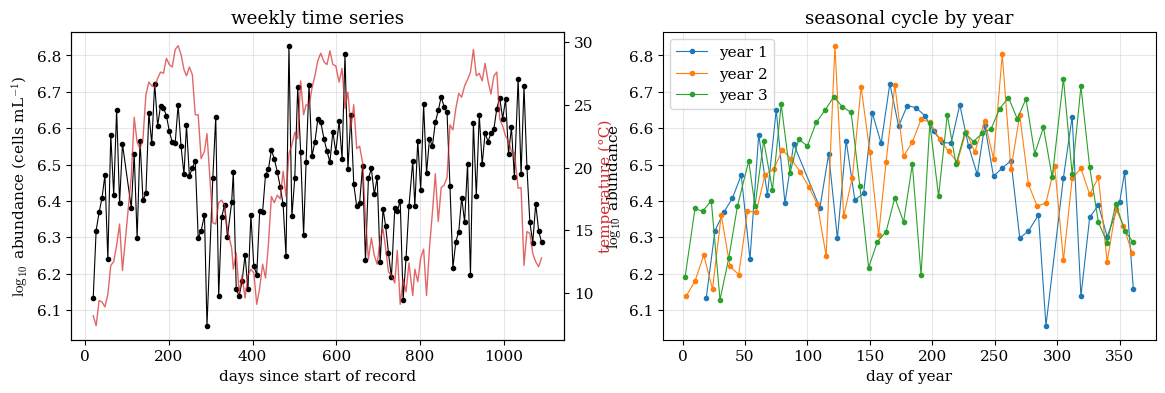

In [14]:
fig = plt.figure(figsize=(14, 4))

ax = plt.subplot(1, 2, 1)
ax.plot(df["YearDay"], df["logB"], "k.-", lw=0.8, label=r"$\log_{10}$ abundance")
ax.set_xlabel("days since start of record")
ax.set_ylabel(r"$\log_{10}$ abundance (cells mL$^{-1}$)")
ax2 = ax.twinx()
ax2.plot(df["YearDay"], df["Temp"], color="tab:red", lw=1.0, alpha=0.7)
ax2.set_ylabel("temperature (°C)", color="tab:red")
ax.set_title("weekly time series")
ax.grid(alpha=0.3)

ax = plt.subplot(1, 2, 2)
for yr, c in zip([1, 2, 3], ["tab:blue", "tab:orange", "tab:green"]):
    sub = df[df["year"] == yr]
    ax.plot(sub["doy"], sub["logB"], ".-", color=c, lw=0.8, label=f"year {yr}")
ax.set_xlabel("day of year")
ax.set_ylabel(r"$\log_{10}$ abundance")
ax.set_title("seasonal cycle by year")
ax.legend()
ax.grid(alpha=0.3)

**Figure 1.** Left: weekly time series of $\log_{10}$ abundance (black) and water temperature (red). Right: $\log_{10}$ abundance as a function of day of year, shown separately for each of the three years.

Mean $\log_{10}$ abundance is 6.54 in summer ($n = 40$) and 6.31 in winter ($n = 36$). The seasonal difference of 0.24 dex (a factor of 1.72) is 2.1 times the mean within-season standard deviation (0.12 dex in summer, 0.10 dex in winter). Annual means for years 1 to 3 are 6.46, 6.45 and 6.48, so there is no detectable interannual trend. Over the full record, abundance and temperature are correlated with $r = 0.46$. The median absolute change between consecutive samples is 0.10 dex; the largest is 0.58 dex (a factor of 3.8). Abundance is higher in the warm half of the year, but the seasonal signal is noisy and its repeatability from year to year is weak (Figure 1, right). Week-to-week changes of a factor of two occur in all seasons (e.g. the pronounced maxima in the second year). The predictive value of the seasonal cycle is quantified in 4.

In [17]:
summer = df[df["doy"].between(152, 243)]["logB"]
winter = df[(df["doy"] <= 59) | (df["doy"] >= 335)]["logB"]
yr_means = df.groupby("year")["logB"].mean()
dlog = np.abs(np.diff(df["logB"]))
d_sw = summer.mean() - winter.mean()

print(f"summer (doy 152-243): mean {summer.mean():.2f}, SD {summer.std():.2f}, n = {len(summer)}")
print(f"winter (doy <= 59 or >= 335): mean {winter.mean():.2f}, SD {winter.std():.2f}, n = {len(winter)}")
print(f"summer - winter: {d_sw:.2f} dex (factor {10**d_sw:.2f}); ratio to mean within-season SD: {d_sw / np.mean([summer.std(), winter.std()]):.1f}")
print("annual means (years 1-3):", ", ".join(f"{v:.2f}" for v in yr_means))
print(f"corr(log abundance, temperature) = {df['logB'].corr(df['Temp']):.2f}")
print(f"week-to-week change: median {np.median(dlog):.2f} dex, maximum {dlog.max():.2f} dex (factor {10**dlog.max():.1f})")

summer (doy 152-243): mean 6.54, SD 0.12, n = 40
winter (doy <= 59 or >= 335): mean 6.31, SD 0.10, n = 36
summer - winter: 0.24 dex (factor 1.72); ratio to mean within-season SD: 2.1
annual means (years 1-3): 6.46, 6.45, 6.48
corr(log abundance, temperature) = 0.46
week-to-week change: median 0.10 dex, maximum 0.58 dex (factor 3.8)




### 2.2 Skewness and variable transformation

Several nutrient concentrations are strongly right-skewed (rare large pulses on top of a low background). Gradient-based training and linear regression are sensitive to such extreme values. Chlorophyll and the four nutrients are therefore transformed as $\log_{10}(x + 0.01)$; the offset is required because `NO2.NO3` and `PO4` contain zeros. Skewness before and after the transformation is compared below, together with that of the target.

In [20]:
log_cols = ["Chlorophyll", "NH4", "NO2.NO3", "PO4", "SiO4"]

X_df = df[feats].copy()
for c in log_cols:
    X_df[c] = np.log10(X_df[c] + 0.01)

skew = pd.DataFrame({"raw": df[log_cols].skew(), "log10(x + 0.01)": X_df[log_cols].skew()}).round(2)
print(skew.T.to_string())
print(f"\nabundance skewness : raw {df['Bacteria_abundance'].skew():.2f}, log10 {df['logB'].skew():.2f}")

                 Chlorophyll   NH4  NO2.NO3   PO4  SiO4
raw                     1.09  5.56     5.26  1.86  3.45
log10(x + 0.01)         0.01 -0.32     0.62 -0.73  0.16

abundance skewness : raw 0.55, log10 -0.26


The transformation reduces the skewness of chlorophyll from 1.09 to 0.01, of `NH4` from 5.56 to $-0.32$, of `NO2.NO3` from 5.26 to 0.62, of `PO4` from 1.86 to $-0.73$ and of `SiO4` from 3.45 to 0.16. The skewness of the target changes from 0.55 (raw) to $-0.26$ ($\log_{10}$).
The transformation removes most of the skewness of chlorophyll, `NH4` and `SiO4`. The reduction is less complete for `NO2.NO3` and `PO4`, which contain many zeros or near-zero values and occasional pulses; the transformed variables are nevertheless closer to symmetric than the raw ones. The target is only mildly skewed to begin with, but a logarithmic target is standard for abundance data and allows errors to be interpreted as relative (multiplicative) errors, so it is retained. The whole record was used for this exploration, but no model parameters are estimated from it; the scaling parameters are estimated from the training period only (section 3.2).

-----------------------
# 3. Evaluation set-up

## 3.1 Train / validation / test split: chronological

A random split is inappropriate for time series: neighbouring weeks are correlated (the lag-1 autocorrelation of the target is computed below), so that most test weeks would have their neighbours in the training set and a flexible model could partly interpolate rather than predict. The record is therefore split chronologically into 70% training, 15% validation and 15% test data, so that models are trained on the past, tuned on the intermediate period and evaluated on the final period (Bergmeir and Benitez, 2012; Hyndman and Athanasopoulos, 2021).

A consequence of this design is that the three periods cover different seasons and that the test set is small (24 weeks). This is addressed by a blocked cross-validation as a robustness check (section 5.5) and is discussed under limitations (section    9).

In [24]:
y_all = df["logB"].values
X_all = X_df.values                       # log-transformed features, not yet scaled
n = len(df)
n_tr, n_va = int(0.70 * n), int(0.15 * n)

idx_tr = np.arange(0, n_tr)
idx_va = np.arange(n_tr, n_tr + n_va)
idx_te = np.arange(n_tr + n_va, n)

for name, idx in [("train", idx_tr), ("valid", idx_va), ("test ", idx_te)]:
    print(f"{name}: {len(idx):3d} samples, days {df['YearDay'].iloc[idx[0]]:4d} to {df['YearDay'].iloc[idx[-1]]:4d}"
          f"  (day of year {df['doy'].iloc[idx[0]]:3d} to {df['doy'].iloc[idx[-1]]:3d}), mean log10 abundance {y_all[idx].mean():.3f}")

lag1 = np.corrcoef(y_all[idx_tr][:-1], y_all[idx_tr][1:])[0, 1]
print(f"\nlag-1 autocorrelation of target (training period): {lag1:.2f}")

train: 105 samples, days   19 to  767  (day of year  19 to  37), mean log10 abundance 6.443
valid:  22 samples, days  774 to  921  (day of year  44 to 191), mean log10 abundance 6.477
test :  24 samples, days  928 to 1091  (day of year 198 to 361), mean log10 abundance 6.533

lag-1 autocorrelation of target (training period): 0.40




## 3.2 Scaling

All inputs are standardised to zero mean and unit variance using the training-set mean and standard deviation only, to prevent leakage of test information into the scaling. The target is standardised in the same way, and all errors are reported after conversion back to $\log_{10}$ units (dex), where an error of 0.1 dex corresponds to about 26%. The effect of omitting this step is tested in section 5.4.

In [27]:
scaler_X = StandardScaler().fit(X_all[idx_tr])
Xs = scaler_X.transform(X_all)

y_mu, y_sd = y_all[idx_tr].mean(), y_all[idx_tr].std()
ys = (y_all - y_mu) / y_sd

ytr_s, yva_s, yte_s = ys[idx_tr], ys[idx_va], ys[idx_te]
print(f"target scaling: mean {y_mu:.3f}, std {y_sd:.3f} (so 1 unit of scaled error = {y_sd:.3f} dex)")

target scaling: mean 6.443, std 0.160 (so 1 unit of scaled error = 0.160 dex)




## 3.3 Association between predictors and target (training period only)

Pearson correlations between each (transformed) predictor and $\log_{10}$ abundance, and the most strongly correlated predictor pairs, are computed from the training period only.

In [30]:
train_corr = pd.concat([X_df.iloc[idx_tr], df["logB"].iloc[idx_tr]], axis=1).corr()
c_target = train_corr["logB"].drop("logB").sort_values(ascending=False)
pc = train_corr.loc[feats, feats]
pairs = sorted([(a, b, pc.loc[a, b]) for i, a in enumerate(feats) for b in feats[i + 1:]], key=lambda t: -abs(t[2]))[:6]
print("correlation with log10 abundance:")
print(c_target.round(2).to_string())
print("\nmost strongly correlated predictor pairs:")
for a, b, r in pairs:
    print(f"  {a} - {b}: r = {r:.2f}")

correlation with log10 abundance:
Projected_Daily_Insolation    0.64
Temp                          0.60
Chlorophyll                   0.45
SiO4                          0.42
pH                            0.24
Oxygen_Saturation             0.16
Salinity                      0.13
PO4                           0.10
DIC                           0.08
NH4                           0.05
NO2.NO3                      -0.10
MLLW                         -0.25

most strongly correlated predictor pairs:
  Projected_Daily_Insolation - Temp: r = 0.82
  Salinity - DIC: r = 0.75
  Temp - pH: r = 0.65
  Chlorophyll - SiO4: r = 0.64
  Temp - Chlorophyll: r = 0.60
  Salinity - pH: r = 0.58



## 3.4 Metrics

The primary metric is the root-mean-square error (RMSE) in dex. To make the metric interpretable, a **skill score** relative to a reference that always predicts the training-period mean is also reported,

$$ \text{SS} = 1 - \frac{\text{MSE}_\text{model}}{\text{MSE}_\text{train-mean}}, $$

which is 0 for the reference, 1 for a perfect model and negative for a model worse than the reference. Because the test set contains only 24 points, a 95% bootstrap confidence interval of SS is obtained by resampling the test weeks. The bootstrap treats weeks as independent and therefore probably understates the uncertainty slightly. Differences between two models are assessed with a paired bootstrap of the difference in mean squared error.

In [33]:
def rmse_dex(y_true_s, y_pred_s):
    """RMSE converted back to log10 units"""
    return float(np.sqrt(np.mean((y_true_s - y_pred_s) ** 2)) * y_sd)

def skill(y_true_s, y_pred_s):
    """skill relative to predicting the training mean (which is 0 in scaled units)"""
    return float(1 - np.mean((y_true_s - y_pred_s) ** 2) / np.mean(y_true_s ** 2))

def boot_skill_ci(y_true_s, y_pred_s, B=2000, seed=0):
    """95% bootstrap interval of the skill score, resampling the test points"""
    rng = np.random.default_rng(seed)
    N = len(y_true_s)
    idx = rng.integers(0, N, (B, N))
    ss = 1 - ((y_true_s - y_pred_s) ** 2)[idx].mean(1) / (y_true_s ** 2)[idx].mean(1)
    return tuple(np.percentile(ss, [2.5, 97.5]))

def boot_mse_diff(y_true_s, p_a, p_b, B=2000, seed=0):
    """95% interval of MSE(a) - MSE(b) (paired bootstrap); an interval containing 0 means 'cannot tell a from b'"""
    rng = np.random.default_rng(seed)
    N = len(y_true_s)
    idx = rng.integers(0, N, (B, N))
    d = (y_true_s - p_a) ** 2 - (y_true_s - p_b) ** 2
    return tuple(np.percentile(d[idx].mean(1), [2.5, 97.5]))

results = {}   # everything gets logged in here for the final comparison

def record(name, pv, pt):
    """pv, pt : arrays (n_runs, n_points) of validation/test predictions in scaled units (n_runs = 1 for deterministic methods)"""
    pv, pt = np.atleast_2d(pv), np.atleast_2d(pt)
    per_run_test = [rmse_dex(yte_s, p) for p in pt]
    ens_v, ens_t = pv.mean(0), pt.mean(0)       # ensemble mean over random seeds
    results[name] = dict(val=rmse_dex(yva_s, ens_v), test=rmse_dex(yte_s, ens_t),
                         test_seed_mean=float(np.mean(per_run_test)), test_seed_sd=float(np.std(per_run_test)),
                         skill=skill(yte_s, ens_t), ci=boot_skill_ci(yte_s, ens_t), pred=ens_t, pred_val=ens_v)
    return results[name]

## 3.5 Training procedure

All networks share one training routine: full-batch optimisation of the mean squared error with Adam (Kingma and Ba, 2015); mini-batches are unnecessary for ~100 training samples. Two standard additions are included and tested as ablations in section 5.4:

* **Early stopping** The validation loss is monitored, the weights from the epoch with the lowest validation loss are retained, and training stops when no improvement occurs for `patience` epochs. This limits overfitting, which is a substantial risk for ~100 samples.
* **Weight decay**, i.e. an $L_2$ penalty on the weights, as an optional regulariser.

Because the data set is small, the outcome of a single training run depends noticeably on the random weight initialisation. Every model is therefore trained from several random seeds, and both the mean and spread of the metric over seeds and the error of the ensemble-mean prediction are reported.

In [36]:
def to_t(a):
    return torch.as_tensor(np.asarray(a), dtype=torch.float32)

def train_model(model, X_tr, y_tr, X_va=None, y_va=None, lr=3e-3, weight_decay=0.0,
                epochs=400, patience=40, restore_best=True):
    """full-batch training with Adam + MSE. If a validation set is given, track it and apply early stopping.
       returns model, training loss curve, validation loss curve, epoch of best validation loss"""
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    J = nn.MSELoss()
    train_J, valid_J = [], []
    best_J, best_epoch, best_state, wait = np.inf, 0, None, 0

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        loss = J(model(X_tr), y_tr)
        loss.backward()
        opt.step()
        train_J.append(loss.item())

        if X_va is None:
            continue
        model.eval()
        with torch.no_grad():
            v = J(model(X_va), y_va).item()
        valid_J.append(v)
        if v < best_J - 1e-6:
            best_J, best_epoch, wait = v, epoch, 0
            best_state = {k: p.detach().clone() for k, p in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break

    if restore_best and best_state is not None:
        model.load_state_dict(best_state)
    return model, np.array(train_J), np.array(valid_J), best_epoch

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(X).numpy()

def run_seeds(build, data, seeds, **kw):
    """train the model returned by build() once per seed.
       data = (X_tr, y_tr, X_va, y_va, X_te, y_te) as tensors; returns val preds, test preds, best epochs"""
    pv, pt, eps = [], [], []
    for s in seeds:
        torch.manual_seed(s)
        model = build()
        model, _, _, best_epoch = train_model(model, data[0], data[1], data[2], data[3], **kw)
        pv.append(predict(model, data[2]))
        pt.append(predict(model, data[4]))
        eps.append(best_epoch)
    return np.array(pv), np.array(pt), eps

def heatmap(ax, M, xlabels, ylabels, xlabel, ylabel, title):
    """annotated heatmap, lowest value outlined"""
    im = ax.imshow(M, cmap="viridis_r", aspect="auto")
    ax.set_xticks(range(len(xlabels))); ax.set_xticklabels(xlabels)
    ax.set_yticks(range(len(ylabels))); ax.set_yticklabels(ylabels)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.3f}", ha="center", va="center", color="w", fontsize=9)
    i0, j0 = np.unravel_index(np.argmin(M), M.shape)
    ax.add_patch(plt.Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, ec="r", lw=2))
    plt.colorbar(im, ax=ax)

SEEDS_FINAL = range(8)    # number of random initialisations for the final runs of each model
SEEDS_SEARCH = range(3)   # cheaper, used inside hyper-parameter searches

-----------------------
# 4. Baselines

A reference level of skill is established before any neural network is fitted. Four baselines are used:

1. **Training mean** (climatology): the training-period average is predicted at all times.
2. **Persistence**: the abundance of week $t$ is predicted to equal that of week $t-1$. This is the standard reference for time series and requires the previous week's abundance.
3. **Seasonal climatology**: the mean of the training samples within $\pm 21$ days of the same day of year. If abundance were predominantly a repeatable seasonal cycle, this baseline would perform well.
4. **Ridge regression** All twelve environmental variables: a linear model with an $L_2$ penalty whose strength is chosen on the validation set. It is the benchmark that a network must outperform to justify its complexity, and it is the limit to which a network without hidden layers reduces. A variant with the previous week's abundance as an additional predictor is also evaluated.

In [39]:
ALPHAS = [0.1, 1, 3, 10, 30, 100, 300, 1000]

def ridge_select(Ztr, ytr, Zva, yva, Zte):
    """ridge regression, strength chosen by validation RMSE; returns alpha, val prediction, test prediction"""
    best = None
    for a in ALPHAS:
        r = Ridge(alpha=a).fit(Ztr, ytr)
        e = np.mean((yva - r.predict(Zva)) ** 2)
        if best is None or e < best[0]:
            best = (e, a, r)
    _, a, r = best
    return a, r.predict(Zva), r.predict(Zte)

# 1) training mean: zero in scaled units
record("Training mean", np.zeros(len(idx_va)), np.zeros(len(idx_te)))

# 2) persistence: y(t) = y(t-1)
record("Persistence", ys[idx_va - 1], ys[idx_te - 1])

# 3) seasonal climatology from the training period
def seasonal_clim(idx, half_window=21):
    out = []
    for d in df["doy"].values[idx]:
        dist = np.abs(df["doy"].values[idx_tr] - d)
        dist = np.minimum(dist, 365 - dist)          # wrap around the year
        out.append(ytr_s[dist <= half_window].mean())
    return np.array(out)
record("Seasonal climatology", seasonal_clim(idx_va), seasonal_clim(idx_te))

# 4) ridge on the environment only, and with last week's abundance as an extra predictor
ridge_alpha, pv, pt = ridge_select(Xs[idx_tr], ytr_s, Xs[idx_va], yva_s, Xs[idx_te])
record("Ridge (env only)", pv, pt)

ys_lag = np.concatenate([[0.0], ys[:-1]])      # y(t-1), first entry set to the training mean (0)
Xs_lag = np.column_stack([Xs, ys_lag])
alpha_lag, pv, pt = ridge_select(Xs_lag[idx_tr], ytr_s, Xs_lag[idx_va], yva_s, Xs_lag[idx_te])
record("Ridge (env + last week)", pv, pt)

base = pd.DataFrame({k: {"val RMSE (dex)": v["val"], "test RMSE (dex)": v["test"], "test skill": v["skill"],
                         "skill 95% CI": f"[{v['ci'][0]:.2f}, {v['ci'][1]:.2f}]"} for k, v in results.items()}).T
base = base.astype({"val RMSE (dex)": float, "test RMSE (dex)": float, "test skill": float})
print(f"ridge strength chosen on validation set: alpha = {ridge_alpha} (env only), {alpha_lag} (env + last week)\n")
base.round(3)

ridge strength chosen on validation set: alpha = 1000 (env only), 100 (env + last week)



,val RMSE (dex),test RMSE (dex),test skill,skill 95% CI
Training mean,0.149,0.160,0.000,"[0.00, 0.00]"
Persistence,0.141,0.164,-0.043,"[-0.92, 0.49]"
Seasonal climatology,0.189,0.146,0.175,"[-0.17, 0.54]"
Ridge (env only),0.155,0.148,0.144,"[0.07, 0.24]"
Ridge (env + last week),0.150,0.122,0.425,"[0.23, 0.64]"


**Table 1.** Validation and test RMSE (dex), test skill and 95% bootstrap interval of the skill for the baselines (printed above).

The training mean has an RMSE of 0.149 dex (validation) and 0.160 dex (test). Persistence gives 0.141 and 0.164 dex (test skill $-0.04$, 95% CI $-0.92$ to 0.49); the seasonal climatology 0.189 and 0.146 dex (skill 0.18, CI $-0.17$ to 0.54); ridge on the environment alone 0.155 and 0.148 dex (skill 0.14, CI 0.07 to 0.24); and ridge with the previous week's abundance 0.150 and 0.122 dex (skill 0.43, CI 0.23 to 0.64). The ridge penalty selected on the validation set lies at the upper end of the grid ($\alpha = 1000$ for the environment alone, $\alpha = 100$ with the lagged abundance).



-----------------------
# 5. Multi-layer perceptrons

## 5.1 Motivation

Ridge regression assumes that $\log_{10}$ abundance is a linear function of the transformed environmental variables. Biological responses are rarely linear: growth responds to temperature in a saturating and then declining manner, and the effect of nutrients plausibly depends on the availability of organic carbon. An MLP with a nonlinear activation function can represent interactions and saturation without their functional form being prescribed. The associated risk is overfitting, since there are 12 inputs and ~100 training samples.

### Model definition and objective

For a standardised input vector $\mathbf{x} \in \mathbb{R}^{12}$, an MLP with one hidden layer of width $H$ computes

$$ \hat{y} = \mathbf{w}_2^{\top}\, \sigma\!\left(W_1 \mathbf{x} + \mathbf{b}_1\right) + b_2, \qquad \sigma(z) = \max(0, z), $$

and deeper networks stack further layers of the same form. Without the nonlinearity $\sigma$, the composition of affine maps is itself affine, so a deep network without activation functions is equivalent to a linear regression. The parameters $\theta$ are obtained by minimising the regularised mean squared error

$$ J(\theta) = \frac{1}{N} \sum_{i=1}^{N} \left(\hat{y}_i - y_i\right)^2 + \lambda \lVert \theta \rVert_2^2 , $$

where $\lambda$ is the weight decay. Minimisation uses Adam with early stopping on the validation period. The class below covers all variants: `hidden = ()` yields a linear model fitted by gradient descent and `act = None` removes the activation function.

In [43]:
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(16,), act=nn.ReLU):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if act is not None:
                layers.append(act())
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

D_flat = (to_t(Xs[idx_tr]), to_t(ytr_s), to_t(Xs[idx_va]), to_t(yva_s), to_t(Xs[idx_te]), to_t(yte_s))

## 5.2 Effect of depth and nonlinearity

Four variants, each trained from eight random initialisations, are compared: (i) no hidden layer (linear model); (ii) two hidden layers *without* activation functions, which collapses mathematically to a single linear map, so that behaviour equal to (i) is expected; (iii) one hidden layer of 16 ReLU units; and (iv) two hidden layers (32, 16) with ReLU.

In [46]:
variants = {"MLP linear (no hidden layer)": dict(hidden=()),
            "MLP 2 layers, no activation": dict(hidden=(16, 16), act=None),
            "MLP 1 hidden layer (16, ReLU)": dict(hidden=(16,)),
            "MLP 2 hidden layers (32, 16, ReLU)": dict(hidden=(32, 16))}

for name, kw in variants.items():
    pv, pt, _ = run_seeds(lambda: MLP(n_feat, **kw), D_flat, SEEDS_FINAL)
    record(name, pv, pt)

pd.DataFrame({k: {"val RMSE (dex)": results[k]["val"], "test RMSE, mean over seeds": results[k]["test_seed_mean"],
                  "test RMSE, spread over seeds": results[k]["test_seed_sd"], "test RMSE, ensemble mean": results[k]["test"]}
              for k in variants}).T.round(3)

,val RMSE (dex),"test RMSE, mean over seeds","test RMSE, spread over seeds","test RMSE, ensemble mean"
MLP linear (no hidden layer),0.130,0.153,0.026,0.132
"MLP 2 layers, no activation",0.134,0.148,0.020,0.132
"MLP 1 hidden layer (16, ReLU)",0.118,0.156,0.023,0.136
"MLP 2 hidden layers (32, 16, ReLU)",0.107,0.127,0.015,0.117


**Table 2.** Validation RMSE and test RMSE (dex) of four MLP variants, each trained from eight random initialisations. "Mean over seeds" and "spread over seeds" refer to single runs; "ensemble mean" is the RMSE of the mean prediction of the eight runs.

The linear network and the two-layer network without activation function yield indistinguishable errors: 0.153 ± 0.026 and 0.148 ± 0.020 dex for single runs (mean ± standard deviation over seeds) and 0.132 dex for both ensembles. The (32, 16) ReLU network reaches 0.127 ± 0.015 dex (ensemble 0.117 dex), whereas the network with a single hidden layer of 16 units gives 0.156 ± 0.023 dex (ensemble 0.136 dex), no better than the linear one. Validation RMSE ranges from 0.107 to 0.134 dex for the networks, below that of every baseline (0.141 dex or more).



## 5.3 Sensitivity to hyper-parameters

The two hyper-parameters expected to matter most for such a small data set are the hidden-layer **width** (capacity) and the **weight decay** (regularisation). Both are varied for the one-hidden-layer network, with the validation RMSE averaged over three seeds per setting. Selection is based on the validation RMSE only; the test set is not used.

best on validation: width = 64, weight decay = 0.001
range of the validation RMSE over the whole grid: 0.116 to 0.145 dex


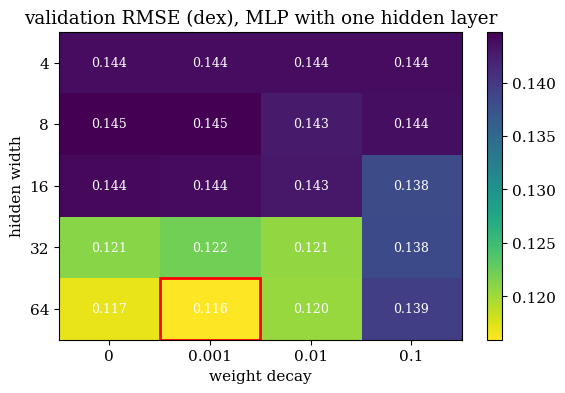

In [48]:
widths = [4, 8, 16, 32, 64]
wds = [0.0, 1e-3, 1e-2, 1e-1]

grid_val = np.zeros((len(widths), len(wds)))
for i, w in enumerate(widths):
    for j, wd in enumerate(wds):
        pv, _, _ = run_seeds(lambda: MLP(n_feat, hidden=(w,)), D_flat, SEEDS_SEARCH, weight_decay=wd)
        grid_val[i, j] = np.mean([rmse_dex(yva_s, p) for p in pv])

i_b, j_b = np.unravel_index(np.argmin(grid_val), grid_val.shape)
w_best, wd_best = widths[i_b], wds[j_b]

fig = plt.figure(figsize=(6.5, 4))
ax = plt.axes()
heatmap(ax, grid_val, [f"{w:g}" for w in wds], [str(w) for w in widths], "weight decay", "hidden width",
        "validation RMSE (dex), MLP with one hidden layer")
print(f"best on validation: width = {w_best}, weight decay = {wd_best}")
print(f"range of the validation RMSE over the whole grid: {grid_val.min():.3f} to {grid_val.max():.3f} dex")

**Figure 2.** Validation RMSE (dex) of the one-hidden-layer MLP as a function of hidden width and weight decay (mean of three random initialisations). The lowest value is outlined in red.

The validation RMSE ranges from 0.116 to 0.145 dex, with its minimum at width 64 and weight decay $10^{-3}$. The dependence on width is step-like: networks with 4–16 hidden units give 0.143–0.145 dex for weight decays up to 0.01, only slightly below the validation RMSE of the training mean (0.149 dex), whereas networks with 32 or 64 units give 0.116–0.122 dex, about 0.025 dex (17%) lower. A weight decay of 0.1 removes this advantage (0.138–0.144 dex at all widths), consistent with excessive shrinkage towards a constant prediction, whereas weight decays between 0 and 0.01 are practically equivalent (0.116–0.120 dex at width 64).


In [50]:
pv, pt, ep = run_seeds(lambda: MLP(n_feat, hidden=(w_best,)), D_flat, SEEDS_FINAL, weight_decay=wd_best)
mlp_name = f"MLP best (width {w_best}, wd {wd_best:g})"
r = record(mlp_name, pv, pt)
print(f"{mlp_name}: test RMSE {r['test']:.3f} dex (ensemble), {r['test_seed_mean']:.3f} +/- {r['test_seed_sd']:.3f} (single runs); "
      f"skill {r['skill']:.2f}, 95% CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]")
print(f"early stopping epochs over seeds: {ep}")

MLP best (width 64, wd 0.001): test RMSE 0.121 dex (ensemble), 0.126 +/- 0.005 (single runs); skill 0.43, 95% CI [0.06, 0.69]
early stopping epochs over seeds: [248, 276, 44, 47, 48, 90, 48, 34]




## 5.4 Ablations: input standardisation and early stopping

The justification for two design choices is tested explicitly.

* **Without standardisation.** The raw inputs differ in scale by orders of magnitude (DIC of order 2000, pH varying by ~0.1, salinity by a few units). In the first layer this leads to an ill-conditioned loss surface, and variables with large numerical values dominate irrespective of their information content.
* **Without early stopping.** A wide network trained for many epochs on ~100 samples can fit noise in the training set. The expected signature is a training loss that continues to decrease while the validation loss rises (classical overfitting). Whether this occurs is tested by training the width-64 network for 1500 epochs.

In [52]:
# (i) no standardisation of the inputs (target still scaled), same architecture and settings as the selected MLP
D_unscaled = (to_t(X_all[idx_tr]), to_t(ytr_s), to_t(X_all[idx_va]), to_t(yva_s), to_t(X_all[idx_te]), to_t(yte_s))
pv_u, pt_u, _ = run_seeds(lambda: MLP(n_feat, hidden=(w_best,)), D_unscaled, SEEDS_FINAL, weight_decay=wd_best)
r_u = record("MLP best, inputs NOT standardised", pv_u, pt_u)
print(f"without standardisation: test RMSE {r_u['test_seed_mean']:.3f} +/- {r_u['test_seed_sd']:.3f} dex  "
      f"(with: {results[mlp_name]['test_seed_mean']:.3f} +/- {results[mlp_name]['test_seed_sd']:.3f})")

# (ii) no early stopping: a wide network trained for 1500 epochs, final weights kept
torch.manual_seed(0)
m_long = MLP(n_feat, hidden=(64,))
m_long, trJ, vaJ, be = train_model(m_long, *D_flat[:4], epochs=1500, patience=10**9, restore_best=False)
test_long = rmse_dex(yte_s, predict(m_long, D_flat[4]))

torch.manual_seed(0)
m_es = MLP(n_feat, hidden=(64,))
m_es, trJ2, vaJ2, be2 = train_model(m_es, *D_flat[:4], epochs=1500, patience=40)
test_es = rmse_dex(yte_s, predict(m_es, D_flat[4]))

print(f"training loss at epoch 1500: {trJ[-1]:.1e}; validation loss minimum at epoch {np.argmin(vaJ)}, value {vaJ.min():.3f}; at epoch 1500 it is {vaJ[-1]:.3f}")
print(f"early stopping selects epoch {be2}")
print(f"test RMSE: {test_long:.3f} dex if trained to the end vs {test_es:.3f} dex with early stopping")

without standardisation: test RMSE 0.312 +/- 0.265 dex  (with: 0.126 +/- 0.005)
training loss at epoch 1500: 5.3e-11; validation loss minimum at epoch 1342, value 0.514; at epoch 1500 it is 0.514
early stopping selects epoch 211
test RMSE: 0.129 dex if trained to the end vs 0.126 dex with early stopping




## 5.5 Robustness: blocked cross-validation

A single chronological split with 22 + 24 evaluation points is a thin basis for conclusions, and the validation and test periods cover different seasons. As a check independent of one particular split, a **5-fold blocked cross-validation** is performed: the record is divided into five contiguous blocks of ~30 weeks, each block is held out in turn, and the model is trained on the remainder with the scaling re-estimated for each fold. Contiguous blocks keep neighbouring weeks together in the held-out fold. Because the training data include periods *after* the held-out block, this is not a forecast test; it addresses the question of how well the environment explains abundance in a period unseen by the model.

The MLP uses the selected width and weight decay with a fixed number of epochs (the median early-stopping epoch from section 5.3), because no separate validation set is available within each fold. For ridge, the penalty is chosen within each training set by efficient leave-one-out cross-validation (`RidgeCV`), which is fairer than reusing the penalty selected by the validation period in section 4 (which lay at the edge of the grid).

In [54]:
folds = np.array_split(np.arange(n), 5)
n_ep = int(np.median(ep)) + 1
rows = []
for f, te_i in enumerate(folds):
    tr_i = np.setdiff1d(np.arange(n), te_i)
    sc = StandardScaler().fit(X_all[tr_i])
    mu, sd = y_all[tr_i].mean(), y_all[tr_i].std()
    Xa, Xb = sc.transform(X_all[tr_i]), sc.transform(X_all[te_i])
    ya, yb = (y_all[tr_i] - mu) / sd, (y_all[te_i] - mu) / sd

    rm_mean = np.sqrt(np.mean(yb ** 2)) * sd
    rm_ridge = np.sqrt(np.mean((yb - RidgeCV(alphas=ALPHAS).fit(Xa, ya).predict(Xb)) ** 2)) * sd

    preds = []
    for s in range(5):
        torch.manual_seed(s)
        m = MLP(n_feat, hidden=(w_best,))
        m, _, _, _ = train_model(m, to_t(Xa), to_t(ya), epochs=n_ep, weight_decay=wd_best)
        preds.append(predict(m, to_t(Xb)))
    rm_mlp = np.sqrt(np.mean((yb - np.mean(preds, 0)) ** 2)) * sd
    rows.append(dict(fold=f + 1, days=f"{df['YearDay'].iloc[te_i[0]]}-{df['YearDay'].iloc[te_i[-1]]}",
                     mean=rm_mean, ridge=rm_ridge, MLP=rm_mlp))

cv = pd.DataFrame(rows).set_index("fold")
cv.loc["average"] = ["", cv["mean"].mean(), cv["ridge"].mean(), cv["MLP"].mean()]
print("held-out RMSE (dex) per block:")
cv.round(3)

held-out RMSE (dex) per block:


,days,mean,ridge,MLP
fold,,,,
1,19-242,0.149,0.153,0.146
2,249-459,0.199,0.170,0.152
3,466-670,0.158,0.110,0.112
4,677-879,0.154,0.108,0.087
5,886-1091,0.153,0.161,0.138
average,,0.163,0.140,0.127


**Table 3.** Held-out RMSE (dex) of the training-mean reference, ridge regression (penalty chosen by internal cross-validation) and the MLP (width 64, weight decay $10^{-3}$, five initialisations) in 5-fold blocked cross-validation. "days" denotes the held-out block.

The mean reference has a held-out RMSE of 0.149–0.199 dex across blocks (average 0.163 dex). Averaged over the blocks, ridge reaches 0.140 dex and the MLP 0.127 dex, corresponding to skill scores (in terms of MSE) of about 0.26 and 0.39 relative to the mean reference, and to a 9% lower RMSE for the MLP than for ridge. Ridge outperforms the mean reference in three of five blocks (blocks 2–4) and is worse in blocks 1 and 5. The MLP outperforms the mean reference in all five blocks and ridge in four of five (in block 3 the two are essentially equal: 0.112 against 0.110 dex). Block 5 (days 886–1091) overlaps with the test period of the chronological split; there ridge (0.161 dex) is worse than the mean reference (0.153 dex) and the MLP (0.138 dex) is better, in agreement with the single split.


## 5.6 Diagnostics: learning curves and test-period predictions

Figure 3 shows (i) learning curves (training and validation loss, the epoch selected by early stopping, and the validation loss of the constant predictor for reference), which indicate whether the network learns something that generalises, and (ii) test-period predictions against observations. From the predictions the following diagnostics are computed: the correlation $r$; the bias (mean error); the amplitude ratio (standard deviation of predictions divided by that of observations); and the calibration slope, i.e. the slope of the regression of observations on predictions. A slope of 1 indicates correctly scaled predictions, a slope below 1 over-dispersed predictions (too large a variance) and a slope above 1 damped predictions. The same diagnostics are used for the CNN (section 7) and the recurrent networks (section 8). Learning curves are computed from five fresh initialisations; predictions are ensemble means.

In [57]:
SEEDS_CURVE = range(5)
obs = y_all[idx_te]
days = df["YearDay"].values[idx_te]
const_val = float(np.mean(yva_s ** 2))          # validation loss of the constant (training-mean) predictor

def curves(build, data, seeds, **kw):
    """train one network per seed and keep the learning curves: list of (train loss, validation loss, selected epoch)"""
    out = []
    for s in seeds:
        torch.manual_seed(s)
        m = build()
        m, trJ, vaJ, be = train_model(m, data[0], data[1], data[2], data[3], **kw)
        out.append((trJ, vaJ, be))
    return out

def plot_curves(ax, cur, title, ref=True):
    for trJ, vaJ, be in cur:
        ax.plot(trJ, color="tab:blue", alpha=0.35, lw=1)
        ax.plot(vaJ, color="tab:orange", alpha=0.35, lw=1)
        ax.plot(be, vaJ[be], "k.", ms=6)
    ax.plot([], [], color="tab:blue", label="training")
    ax.plot([], [], color="tab:orange", label="validation")
    ax.plot([], [], "k.", label="selected epoch")
    if ref:
        ax.axhline(const_val, color="k", ls=":", lw=1, label="constant predictor")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("MSE (standardised units)")
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(alpha=0.3)

def lc_stats(cur):
    be = np.array([c[2] for c in cur])
    tr_sel = np.array([c[0][c[2]] for c in cur])
    va_sel = np.array([c[1][c[2]] for c in cur])
    return dict(be_med=int(np.median(be)), be_min=int(be.min()), be_max=int(be.max()),
                tr=float(np.median(tr_sel)), va=float(np.median(va_sel)),
                gain=float(100 * (1 - np.median(va_sel) / const_val)))

def to_dex(p):
    return p * y_sd + y_mu

def pred_metrics(p_s):
    pr = to_dex(p_s)
    return dict(r=float(np.corrcoef(pr, obs)[0, 1]), rmse=float(np.sqrt(np.mean((pr - obs) ** 2))),
                bias=float(np.mean(pr - obs)), slope=float(np.polyfit(pr, obs, 1)[0]), amp=float(pr.std() / obs.std()))

def plot_scatter(ax, named, title):
    lo, hi = obs.min() - 0.05, obs.max() + 0.05
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.8, label="1:1")
    for name, p_s, colour in named:
        ax.scatter(obs, to_dex(p_s), s=28, color=colour, alpha=0.8, label=name)
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel(r"observed $\log_{10}$ abundance"); ax.set_ylabel("predicted")
    ax.set_title(title); ax.legend(fontsize=8); ax.grid(alpha=0.3)

def calib_word(m):
    if m["slope"] <= 0.1:
        return "uninformative (no clear positive relation between predictions and observations)"
    if m["slope"] < 0.8:
        return "over-dispersed (predictions vary more than the observations justify)"
    if m["slope"] > 1.25:
        return "damped (predictions vary less than the observations)"
    return "approximately calibrated"

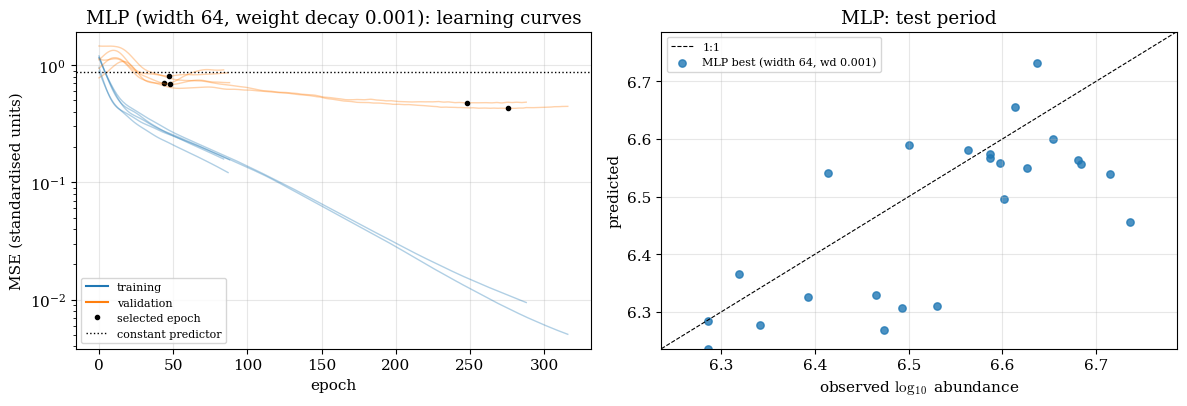

In [58]:
cur_mlp = curves(lambda: MLP(n_feat, hidden=(w_best,)), D_flat, SEEDS_CURVE, weight_decay=wd_best)
m_mlp = pred_metrics(results[mlp_name]["pred"])
err_mlp = to_dex(results[mlp_name]["pred"]) - obs
i_err = int(np.argmax(np.abs(err_mlp)))
s_mlp = lc_stats(cur_mlp)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_curves(axes[0], cur_mlp, f"MLP (width {w_best}, weight decay {wd_best:g}): learning curves")
plot_scatter(axes[1], [(mlp_name, results[mlp_name]["pred"], "tab:blue")], "MLP: test period")
plt.tight_layout()

**Figure 3.** MLP. Left: training and validation loss for five initialisations (the dot marks the epoch selected by early stopping, the dotted line the validation loss of the constant predictor). Right: predicted against observed $\log_{10}$ abundance in the test period for the ensemble mean.

Early stopping selects epoch 48 (median; range 44–276). At that epoch the validation loss is 0.68, which is 22% below that of the constant predictor (0.87), whereas the training loss has decreased to 0.22. On the test period the ensemble has $r = 0.72$, RMSE = 0.121 dex, a bias of $-0.063$ dex, an amplitude ratio of 1.06 and a calibration slope of 0.68. The largest single error is $-0.28$ dex (predicted minus observed) at day 1035, and the median absolute error is 0.082 dex. The training loss is well below the validation loss, i.e. the network fits the training weeks much better than unseen weeks. The calibration slope below 1 together with an amplitude ratio close to 1 indicates over-dispersed predictions: the predicted variability is comparable to the observed variability, but only partly in phase with it ($r = 0.72$). The negative bias is consistent with the higher mean abundance of the test period relative to the training period (section 3.1).

-----------------------
# 6. Autoencoders

## 6.1 Motivation

Section 3.3 showed that the predictors are substantially redundant (temperature and insolation, salinity and DIC, chlorophyll and silicate). An autoencoder compresses the twelve variables through a narrow **bottleneck** of $L$ latent variables and reconstructs all twelve from them. It is trained without access to the target and is therefore an *unsupervised* dimensionality reduction. Two questions are addressed:

1. **How many independent degrees of freedom do the environmental data contain?** The reconstruction error as a function of $L$ is compared with that of **PCA**, the linear counterpart. An autoencoder with linear activations spans the same subspace as PCA so any advantage of the autoencoder must arise from its nonlinearity (here `tanh`; Hinton and Salakhutdinov, 2006).
2. **Is the compressed description sufficient to predict abundance?** The latent variables are used as inputs to a ridge regression, which is compared with using all twelve variables.

The autoencoder is fitted on the training period only, with early stopping on the validation period.

### Model definition

Encoder $f_\phi : \mathbb{R}^{12} \to \mathbb{R}^{L}$ and decoder $g_\psi : \mathbb{R}^{L} \to \mathbb{R}^{12}$ each consist of one hidden layer of 16 `tanh` units. Their parameters minimise the mean squared reconstruction error

$$ J(\phi, \psi) = \frac{1}{12N} \sum_{i=1}^{N} \lVert \mathbf{x}_i - g_\psi(f_\phi(\mathbf{x}_i)) \rVert^2 . $$

The PCA counterpart reconstructs using the projection onto the $L$ leading principal axes, $\hat{\mathbf{x}} = U_L U_L^{\top} \mathbf{x}$, which is the optimal *linear* rank-$L$ reconstruction. Because the variables are standardised, a reconstruction MSE of $e$ corresponds approximately to an unexplained variance fraction $e$.

In [61]:
class AE(nn.Module):
    def __init__(self, n_in, latent=2, hidden=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(n_in, hidden), nn.Tanh(), nn.Linear(hidden, latent))
        self.dec = nn.Sequential(nn.Linear(latent, hidden), nn.Tanh(), nn.Linear(hidden, n_in))

    def forward(self, x):
        return self.dec(self.enc(x))

def encode(ae, X):
    ae.eval()
    with torch.no_grad():
        return ae.enc(to_t(X)).numpy()

Xtr_t, Xva_t, Xte_t = to_t(Xs[idx_tr]), to_t(Xs[idx_va]), to_t(Xs[idx_te])

latent_dims = [1, 2, 3, 4, 6]
ae_models, rows = {}, []
ae_preds = {}     # ridge predictions from AE latent codes, for the final comparison
for L in latent_dims:
    # PCA with L components
    pca = PCA(n_components=L).fit(Xs[idx_tr])
    mse_pca = np.mean((Xs[idx_te] - pca.inverse_transform(pca.transform(Xs[idx_te]))) ** 2)
    Zp = pca.transform(Xs)
    _, pv_p, pt_p = ridge_select(Zp[idx_tr], ytr_s, Zp[idx_va], yva_s, Zp[idx_te])

    mse_ae, rm_ae, pvs, pts = [], [], [], []
    for s in range(3):
        torch.manual_seed(s)
        ae = AE(n_feat, latent=L)
        ae, _, _, _ = train_model(ae, Xtr_t, Xtr_t, Xva_t, Xva_t, lr=3e-3, epochs=800, patience=60)
        ae_models[(L, s)] = ae
        mse_ae.append(np.mean((Xs[idx_te] - predict(ae, Xte_t)) ** 2))
        Za = encode(ae, Xs)
        _, pv_a, pt_a = ridge_select(Za[idx_tr], ytr_s, Za[idx_va], yva_s, Za[idx_te])
        pvs.append(pv_a); pts.append(pt_a)
        rm_ae.append(rmse_dex(yte_s, pt_a))
    ae_preds[L] = (np.array(pvs), np.array(pts))
    rows.append(dict(L=L, **{"PCA recon. MSE": mse_pca, "AE recon. MSE": np.mean(mse_ae),
                             "ridge on PCA scores, test RMSE": rmse_dex(yte_s, pt_p),
                             "ridge on AE codes, test RMSE": np.mean(rm_ae)}))

ae_tab = pd.DataFrame(rows).set_index("L")
full_ridge = results["Ridge (env only)"]["test"]
print(f"reference: ridge on all {n_feat} variables, test RMSE = {full_ridge:.3f} dex\n")
ae_tab.round(3)

reference: ridge on all 12 variables, test RMSE = 0.148 dex



,PCA recon. MSE,AE recon. MSE,"ridge on PCA scores, test RMSE","ridge on AE codes, test RMSE"
L,,,,
1,0.622,0.629,0.161,0.161
2,0.469,0.506,0.151,0.158
3,0.415,0.381,0.151,0.155
4,0.259,0.304,0.148,0.154
6,0.101,0.170,0.149,0.153


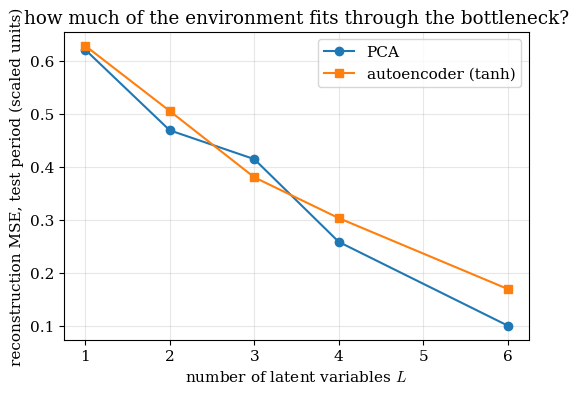

In [62]:
fig = plt.figure(figsize=(6, 4))
ax = plt.axes()
ax.plot(ae_tab.index, ae_tab["PCA recon. MSE"], "o-", label="PCA")
ax.plot(ae_tab.index, ae_tab["AE recon. MSE"], "s-", label="autoencoder (tanh)")
ax.set_xlabel("number of latent variables $L$")
ax.set_ylabel("reconstruction MSE, test period (scaled units)")
ax.set_title("how much of the environment fits through the bottleneck?")
ax.legend(); ax.grid(alpha=0.3)

**Figure 4.** Reconstruction MSE on the test period (in units of the variance of the standardised variables) of PCA and of the tanh autoencoder as a function of the number of latent variables $L$. The table printed above the figure additionally gives the test RMSE of a ridge regression fitted on the latent variables.

The PCA reconstruction MSE decreases from 0.62 at $L = 1$ to 0.47, 0.42, 0.26 and 0.10 at $L = 2, 3, 4, 6$. The autoencoder is better than PCA at one latent size only ($L = 3$: 0.38 against 0.42) and worse at $L = 1, 2, 4$ and 6 (e.g. 0.17 against 0.10 at $L = 6$, about 70% higher).
Four principal components leave about a quarter of the variance unexplained and six leave about a tenth, so the twelve variables are only moderately redundant, with an effective dimension of roughly four to six rather than one or two. The redundancy is essentially linear (temperature follows insolation, salinity follows DIC); with ~100 training samples the additional flexibility of the nonlinear autoencoder cannot be exploited. A likely contributing factor is that validation-based early stopping terminates its training before the PCA optimum is reached.


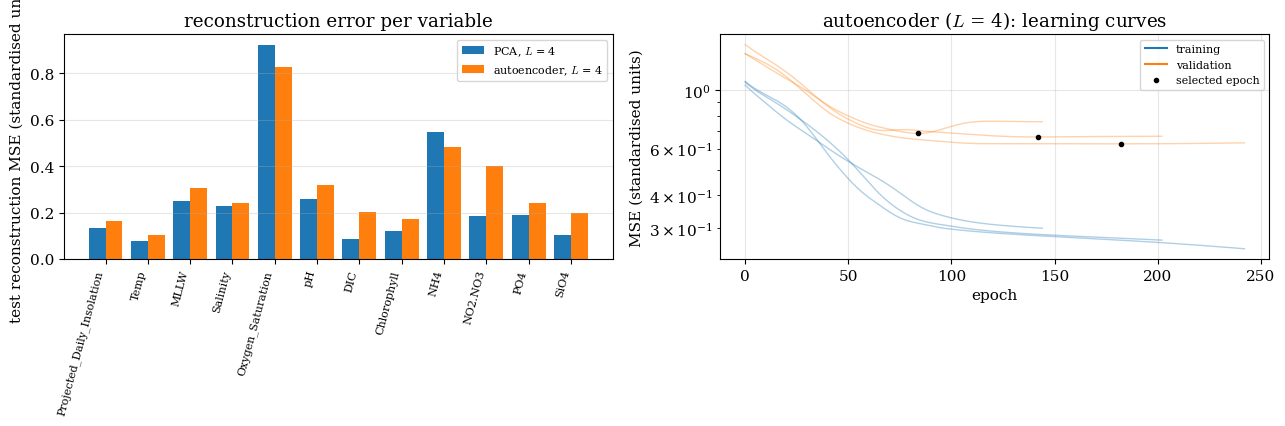

In [64]:
L_show = 4
pca_show = PCA(n_components=L_show).fit(Xs[idx_tr])
rec_pca = pca_show.inverse_transform(pca_show.transform(Xs[idx_te]))
mse_pca_v = ((Xs[idx_te] - rec_pca) ** 2).mean(0)
mse_ae_v = np.mean([((Xs[idx_te] - predict(ae_models[(L_show, s)], Xte_t)) ** 2).mean(0) for s in range(3)], axis=0)

cur_ae = curves(lambda: AE(n_feat, latent=L_show), (Xtr_t, Xtr_t, Xva_t, Xva_t), range(3), lr=3e-3, epochs=800, patience=60)
s_ae = lc_stats(cur_ae)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
xx = np.arange(n_feat)
axes[0].bar(xx - 0.2, mse_pca_v, 0.4, label=f"PCA, $L$ = {L_show}")
axes[0].bar(xx + 0.2, mse_ae_v, 0.4, label=f"autoencoder, $L$ = {L_show}")
axes[0].set_xticks(xx); axes[0].set_xticklabels(feats, rotation=75, ha="right", fontsize=8)
axes[0].set_ylabel("test reconstruction MSE (standardised units)")
axes[0].set_title("reconstruction error per variable"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3, axis="y")
plot_curves(axes[1], cur_ae, f"autoencoder ($L$ = {L_show}): learning curves", ref=False)
plt.tight_layout()

worst_p = [feats[i] for i in np.argsort(mse_pca_v)[::-1][:3]]
best_p = [feats[i] for i in np.argsort(mse_pca_v)[:3]]
n_ae_better = int((mse_ae_v < mse_pca_v).sum())

**Figure 5.** Autoencoder. Left: reconstruction MSE on the test period of each variable for PCA and the autoencoder with $L = 4$ latent variables. Right: training and validation loss of the autoencoder for three initialisations.

*Results.* For $L = 4$, the variables reconstructed worst by PCA are `Oxygen_Saturation`, `NH4` and `pH` (MSE 0.92, 0.55 and 0.26) and those reconstructed best are `Temp`, `DIC` and `SiO4` (MSE 0.08, 0.09 and 0.11). The autoencoder reconstructs 2 of the 12 variables better than PCA, with a mean MSE of 0.30 against 0.26 for PCA. Early stopping selects epoch 142 (range 84–182), with a validation reconstruction loss of 0.66 against a training loss of 0.28.

*Interpretation.* Variables that are collinear with others (temperature, DIC, silicate) are reconstructed well, whereas variables carrying independent information (oxygen saturation, ammonium) are reconstructed poorly. The validation loss is clearly above the training loss, i.e. the autoencoder reconstructs the training weeks better than new weeks, which limits its advantage over linear PCA.

-----------------------
# 7. 1D convolutional networks

## 7.1 Motivation

A convolution is a local pattern detector with shared weights. For a time series, a 1D convolution slides a small filter along the time axis, with the environmental variables as channels (analogous to colour channels in an image). The hypothesis is that abundance responds not only to the instantaneous environment but also to its *recent evolution*, for example a warming trend, the onset of a bloom (rising chlorophyll) or a nutrient pulse a few weeks earlier. A filter of width three weeks can detect such patterns with few weights; in contrast, supplying an MLP with all past weeks as separate inputs makes the number of parameters grow linearly with the window length.

Each sample is a **window** of the preceding $k$ weeks (including the current week) of the 12 variables, and the target is the abundance in the final week. This is a nowcasting set-up in which abundance is not an input. The case $k = 1$ contains no temporal information and serves as the control. Window starts are determined by index, so the irregular sampling gaps (section 2) are ignored, and the first $k-1$ weeks of the record cannot serve as targets. The targets in each period are identical for all $k$ and identical to those used for the MLP, so results are directly comparable.

### Model definition

For a window $\mathbf{x}_{t-k+1}, \dots, \mathbf{x}_t$ with $C$ input channels, a convolutional layer with kernel size 3 and $F$ filters computes the feature maps

$$ h_{f,s} = \sigma\!\left( b_f + \sum_{j=1}^{C} \sum_{\tau=-1}^{1} W_{f,j,\tau}\, x_{j,s+\tau} \right), \qquad f = 1,\dots,F, $$

with zero padding at the window edges. The same weights $W$ are applied at every position $s$ (weight sharing), so the number of filter parameters, $F \cdot C \cdot 3 + F$, is independent of $k$. The $F \times k$ feature maps are flattened and passed to a fully connected head with one hidden layer of 16 units to produce $\hat{y}_t$.

In [69]:
def make_windows(Xs_, ys_, k, ar=False):
    """windows of the last k time steps. ar=True adds last week's abundance y(t-1) as an extra channel (no leakage:
       at step j the channel holds y(j-1), so the window ending at t never contains y(t) itself).
       returns windows (N, k, channels), targets (N,), target indices (N,)"""
    feat = np.column_stack([Xs_, np.concatenate([[0.0], ys_[:-1]])]) if ar else Xs_
    W = np.stack([feat[t - k + 1:t + 1] for t in range(k - 1, len(feat))])
    return W, ys_[k - 1:], np.arange(k - 1, len(feat))

def window_data(k, ar=False):
    W, yw, tw = make_windows(Xs, ys, k, ar)
    out = {"n_ch": W.shape[-1]}
    for key, idx in [("tr", idx_tr), ("va", idx_va), ("te", idx_te)]:
        m = np.isin(tw, idx)
        out[key] = (to_t(W[m]), to_t(yw[m]))
    return out

def as_tuple(D):
    return (*D["tr"], *D["va"], *D["te"])

# sanity check: the validation/test targets must be identical to those used before, whatever the window length
for k_ in [1, 4, 12]:
    D_ = window_data(k_)
    assert np.allclose(D_["va"][1].numpy(), yva_s, atol=1e-5) and np.allclose(D_["te"][1].numpy(), yte_s, atol=1e-5)
print("window targets consistent with the earlier splits; example shape for k = 4:", tuple(window_data(4)["tr"][0].shape))

window targets consistent with the earlier splits; example shape for k = 4: (102, 4, 12)


In [70]:
class CNN1D(nn.Module):
    def __init__(self, n_ch, k, n_filt=8, kernel=3, hidden=16):
        super().__init__()
        # 'same' padding so that the window length is kept, also works for k = 1
        self.conv = nn.Sequential(nn.Conv1d(n_ch, n_filt, kernel, padding=kernel // 2), nn.ReLU())
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(n_filt * k, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):                 # x : (batch, k, channels) -> Conv1d wants (batch, channels, k)
        return self.head(self.conv(x.permute(0, 2, 1))).squeeze(-1)

ks = [1, 2, 4, 8, 12]
cnn_wds = [0.0, 1e-2]
cnn_val = np.zeros((len(ks), len(cnn_wds)))
for i, k in enumerate(ks):
    D = window_data(k)
    for j, wd in enumerate(cnn_wds):
        pv, _, _ = run_seeds(lambda: CNN1D(D["n_ch"], k), as_tuple(D), SEEDS_SEARCH, weight_decay=wd)
        cnn_val[i, j] = np.mean([rmse_dex(yva_s, p) for p in pv])

i_c, j_c = np.unravel_index(np.argmin(cnn_val), cnn_val.shape)
k_cnn, wd_cnn = ks[i_c], cnn_wds[j_c]

print(f"best on validation: k = {k_cnn} weeks, weight decay = {wd_cnn}\n")
print("validation RMSE (dex), mean of 3 initialisations:")
display(pd.DataFrame(cnn_val, index=[f"k = {k}" for k in ks], columns=[f"weight decay {w:g}" for w in cnn_wds]).round(3))

best on validation: k = 1 weeks, weight decay = 0.0

validation RMSE (dex), mean of 3 initialisations:


,weight decay 0,weight decay 0.01
k = 1,0.137,0.137
k = 2,0.148,0.148
k = 4,0.150,0.150
k = 8,0.154,0.154
k = 12,0.145,0.145


**Table 4.** Validation RMSE (dex) of the 1D-CNN as a function of window length $k$ and weight decay (mean of three initialisations; printed above).

The validation RMSE lies between 0.137 and 0.154 dex, and the best value is obtained **without** temporal context, $k = 1$ (0.137 dex). Longer windows are worse: 0.148 ($k = 2$), 0.150 ($k = 4$), 0.154 ($k = 8$) and 0.145 dex ($k = 12$), i.e. 0.008–0.017 dex above the $k = 1$ value; for $k \ge 2$ the values are within 0.005 dex of the training mean (0.149 dex). The two weight decays give identical values to three decimals at every $k$.


In [73]:
D = window_data(k_cnn)
pv, pt, _ = run_seeds(lambda: CNN1D(D["n_ch"], k_cnn), as_tuple(D), SEEDS_FINAL, weight_decay=wd_cnn)
cnn_name = f"1D-CNN best (k {k_cnn}, wd {wd_cnn:g})"
r = record(cnn_name, pv, pt)
print(f"{cnn_name}: test RMSE {r['test']:.3f} dex (ensemble), {r['test_seed_mean']:.3f} +/- {r['test_seed_sd']:.3f} (single runs); "
      f"skill {r['skill']:.2f}, CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]")

1D-CNN best (k 1, wd 0): test RMSE 0.146 dex (ensemble), 0.153 +/- 0.011 (single runs); skill 0.17, CI [0.12, 0.23]


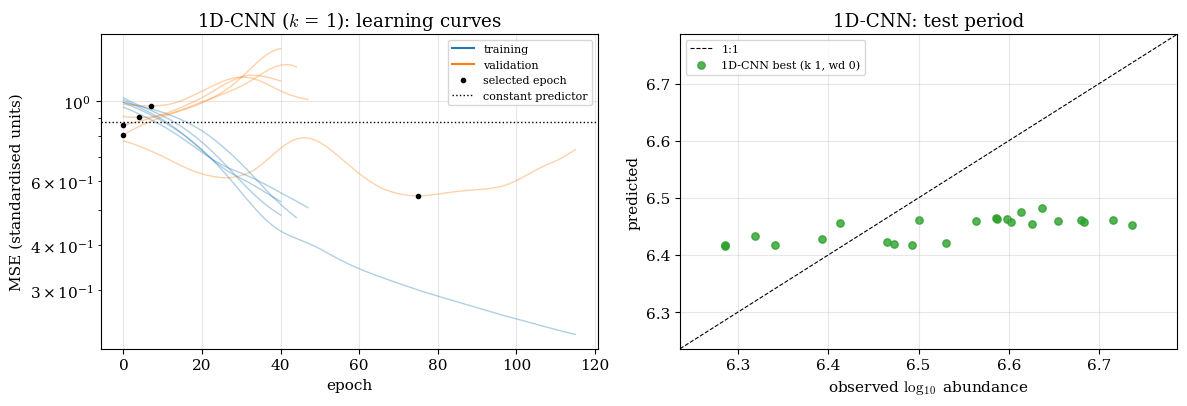

In [74]:
D_c = window_data(k_cnn)
cur_cnn = curves(lambda: CNN1D(D_c["n_ch"], k_cnn), as_tuple(D_c), SEEDS_CURVE, weight_decay=wd_cnn)
m_cnn = pred_metrics(results[cnn_name]["pred"])
s_cnn = lc_stats(cur_cnn)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_curves(axes[0], cur_cnn, f"1D-CNN ($k$ = {k_cnn}): learning curves")
plot_scatter(axes[1], [(cnn_name, results[cnn_name]["pred"], "tab:green")], "1D-CNN: test period")
plt.tight_layout()

**Figure 6.** 1D-CNN. Left: training and validation loss for five initialisations. Right: predicted against observed $\log_{10}$ abundance in the test period for the ensemble mean.

Early stopping selects epoch 4 (range 0–75). At that epoch the validation loss is 0.86, only 2% below that of the constant predictor (0.87), and the training loss is 0.97. On the test period the ensemble has $r = 0.74$, RMSE = 0.146 dex, bias $-0.086$ dex, amplitude ratio 0.16 and calibration slope 4.71. Compared with the MLP (Figure 3: $r = 0.72$, RMSE = 0.121 dex), the CNN has a higher error and a slightly higher correlation.
The early-stopping epoch and the amplitude ratio show that the network stays close to a constant prediction: the predictions are strongly damped (slope $\gg 1$) and their skill derives mainly from a small, correctly phased variation about the training mean. With the selected window of $k = 1$ the convolution has no temporal context, so the network is effectively a small MLP with lower capacity than those of section 5.

-----------------------
# 8. Recurrent networks: RNN, LSTM and GRU

## 8.1 Motivation

A recurrent network processes the window one week at a time and carries a hidden state (memory) from week to week; the final state is used for the prediction. In contrast to the CNN, the memory can in principle integrate over a longer and more flexible period. Two distinct questions are addressed:

1. **Environment only (nowcasting).** The inputs are the same as for the CNN. Does the history of the environment improve the prediction?
2. **Environment plus previous week's abundance (forecast-type set-up).** Bacterial populations have an intrinsic memory (the cells present now descend from those present last week), so the previous abundance is a natural additional predictor, even though persistence alone was weak (section 4). The lagged abundance is added as a thirteenth channel; no information on the target week leaks into the inputs. The relevant baselines are ridge regressions on the same windows.

Three cell types are compared: the plain **RNN** (tanh), the **LSTM** (Hochreiter and Schmidhuber, 1997) and the **GRU** (Cho et al., 2014). The latter two use gates designed to preserve information over many steps and to avoid vanishing gradients. For windows of a few weeks the gradient problem is not severe, so similar behaviour of the three cell types is expected; with so little data, the additional parameters of the gated cells are a potential disadvantage.

### Model definition

All three cell types update a hidden state $\mathbf{h}_s$ as the window is read from $s = t-k+1$ to $s = t$, and the prediction is a linear read-out of the final state, $\hat{y}_t = \mathbf{w}^{\top} \mathbf{h}_t + b$. The plain RNN uses

$$ \mathbf{h}_s = \tanh\!\left( W_x \mathbf{x}_s + W_h \mathbf{h}_{s-1} + \mathbf{b} \right). $$

The LSTM adds a cell state $\mathbf{c}_s$ and input, forget and output gates $\mathbf{i}_s, \mathbf{f}_s, \mathbf{o}_s \in (0,1)^H$ (each a sigmoid of an affine function of $\mathbf{x}_s$ and $\mathbf{h}_{s-1}$):

$$ \mathbf{c}_s = \mathbf{f}_s \odot \mathbf{c}_{s-1} + \mathbf{i}_s \odot \tanh\!\left( W_c \mathbf{x}_s + U_c \mathbf{h}_{s-1} + \mathbf{b}_c \right), \qquad \mathbf{h}_s = \mathbf{o}_s \odot \tanh(\mathbf{c}_s). $$

The GRU merges the cell and hidden states and uses an update gate $\mathbf{u}_s$ and a reset gate, giving $\mathbf{h}_s = (1 - \mathbf{u}_s) \odot \mathbf{h}_{s-1} + \mathbf{u}_s \odot \tilde{\mathbf{h}}_s$ with candidate state $\tilde{\mathbf{h}}_s$. The multiplicative gates allow information to be carried or discarded with fewer vanishing-gradient problems than in the plain RNN, at the cost of roughly three to four times as many parameters for the same hidden size, which is significant for ~100 training windows.

## 8.2 Hyper-parameter search

Window length ($k = 1, 2, 4, 8$ weeks) and hidden size (4, 8, 16, 32) are varied for the LSTM using environmental inputs only; the validation RMSE is averaged over three initialisations.

best on validation: k = 1 weeks, hidden size = 8


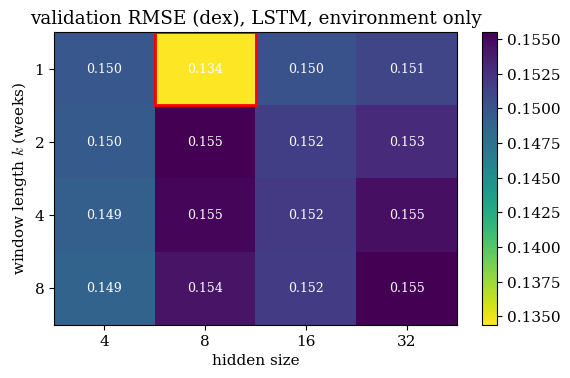

In [80]:
class Recurrent(nn.Module):
    def __init__(self, n_in, hidden=16, kind="lstm"):
        super().__init__()
        cell = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = cell(n_in, hidden, batch_first=True)          # input shape (batch, k, n_in)
        self.head = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)                  # out : (batch, k, hidden); the second output is the final state(s)
        return self.head(out[:, -1, :]).squeeze(-1)

# hyper-parameter search with the LSTM, environment only: window length and hidden size
ks_r = [1, 2, 4, 8]
hs_r = [4, 8, 16, 32]
rnn_val = np.zeros((len(ks_r), len(hs_r)))
for i, k in enumerate(ks_r):
    D = window_data(k)
    for j, h in enumerate(hs_r):
        pv, _, _ = run_seeds(lambda: Recurrent(D["n_ch"], hidden=h, kind="lstm"), as_tuple(D), SEEDS_SEARCH)
        rnn_val[i, j] = np.mean([rmse_dex(yva_s, p) for p in pv])

i_r, j_r = np.unravel_index(np.argmin(rnn_val), rnn_val.shape)
k_rnn, h_rnn = ks_r[i_r], hs_r[j_r]

fig = plt.figure(figsize=(6.5, 3.8))
ax = plt.axes()
heatmap(ax, rnn_val, [str(h) for h in hs_r], [str(k) for k in ks_r], "hidden size", "window length $k$ (weeks)",
        "validation RMSE (dex), LSTM, environment only")
print(f"best on validation: k = {k_rnn} weeks, hidden size = {h_rnn}")

**Figure 7.** Validation RMSE (dex) of the LSTM using only the environmental variables, as a function of window length $k$ and hidden size (mean of three initialisations). The lowest value is outlined.

All cells but one lie between 0.149 and 0.155 dex, i.e. at the validation RMSE of the training mean (0.149 dex). The exception is $k = 1$ with hidden size 8 (0.134 dex); its direct neighbours ($k = 1$ with hidden sizes 4 and 16) give 0.150 dex. Averaged over hidden size, the validation RMSE is 0.146 ($k = 1$), 0.152 ($k = 2$), 0.153 ($k = 4$) and 0.153 dex ($k = 8$); averaged over window length it is 0.149, 0.150, 0.151 and 0.154 dex for hidden sizes 4, 8, 16 and 32.
At these settings the LSTM learns nothing that generalises to the validation period, with a single exception. That minimum is isolated, and since each cell is an average over only three initialisations, it is more probably a favourable draw of the random initialisation than a true optimum. Neither a longer window nor a larger hidden state helps; the slight increase with hidden size is expected when the number of parameters grows while the number of training windows (~100) remains fixed.

Because the selected window is $k = 1$, the recurrent networks below receive a **single** time step and have no recurrence over time; they differ only in how they transform the inputs of one week. The comparison of cell types in Table 5 should therefore be read as a comparison of small one-step nonlinear models. A supplementary experiment with $k = 4$ and $k = 8$, in which memory can act, follows in section 8.4.

## 8.3 Comparison of cell types

The selected window and hidden size are used for all three cell types and both input sets, instead of tuning each separately, so that cell types are compared at the same size (which slightly favours the LSTM, since it was the one tuned). Each combination uses eight seeds. Ridge regression on the flattened windows is the linear baseline for each input set.

In [82]:
rnn_names = []
for ar in [False, True]:
    tag = "env + last week" if ar else "env only"
    D = window_data(k_rnn, ar=ar)

    # linear baseline on the same window, flattened
    flat = [D[key][0].numpy().reshape(len(D[key][0]), -1) for key in ["tr", "va", "te"]]
    _, pv_l, pt_l = ridge_select(flat[0], D["tr"][1].numpy(), flat[1], yva_s, flat[2])
    record(f"Ridge, {k_rnn}-week window ({tag})", pv_l, pt_l)

    for kind in ["rnn", "lstm", "gru"]:
        pv, pt, _ = run_seeds(lambda: Recurrent(D["n_ch"], hidden=h_rnn, kind=kind), as_tuple(D), SEEDS_FINAL)
        name = f"{kind.upper()} ({tag}, k {k_rnn}, h {h_rnn})"
        record(name, pv, pt)
        rnn_names.append(name)

pd.DataFrame({k: {"val RMSE (dex)": results[k]["val"], "test RMSE, mean over seeds": results[k]["test_seed_mean"],
                  "spread over seeds": results[k]["test_seed_sd"], "test RMSE, ensemble": results[k]["test"]}
              for k in [x for x in results if "window" in x] + rnn_names}).T.round(3)

,val RMSE (dex),"test RMSE, mean over seeds",spread over seeds,"test RMSE, ensemble"
"Ridge, 1-week window (env only)",0.155,0.148,0.000,0.148
"Ridge, 1-week window (env + last week)",0.150,0.122,0.000,0.122
"RNN (env only, k 1, h 8)",0.139,0.161,0.026,0.145
"LSTM (env only, k 1, h 8)",0.130,0.145,0.017,0.130
"GRU (env only, k 1, h 8)",0.147,0.156,0.030,0.147
"RNN (env + last week, k 1, h 8)",0.132,0.139,0.031,0.122
"LSTM (env + last week, k 1, h 8)",0.138,0.139,0.029,0.130
"GRU (env + last week, k 1, h 8)",0.136,0.121,0.024,0.110


**Table 5.** Validation and test RMSE (dex) of RNN, LSTM and GRU (window length 1, hidden size 8) with and without the previous week's abundance as an additional input, and of ridge regression on the same inputs. "Mean over seeds" refers to single runs; "ensemble" to the mean prediction of eight runs.

Without the previous week's abundance, the single-run test RMSE is 0.161 (RNN), 0.145 (LSTM) and 0.156 dex (GRU), against 0.148 dex for ridge; the ensembles give 0.145, 0.130 and 0.147 dex. Adding the previous week's abundance improves all models: ridge from 0.148 to 0.122 dex, the RNN to 0.139 (ensemble 0.122), the LSTM to 0.139 (ensemble 0.130) and the GRU to 0.121 dex (ensemble 0.110), the lowest test RMSE of all models in this study. The differences between cell types for the lagged input (at most 0.018 dex) are smaller than the seed-to-seed standard deviation (0.024–0.031 dex).
Without the lagged abundance, none of the recurrent networks is clearly better than the linear model; only the LSTM ensemble is clearly below ridge. With the lagged input, the GRU is the only recurrent network that matches ridge (0.122 dex) as a single run, but the apparent advantage of the gated GRU over the plain RNN is not established, and the LSTM, the other gated cell, is not better than the plain RNN at all.

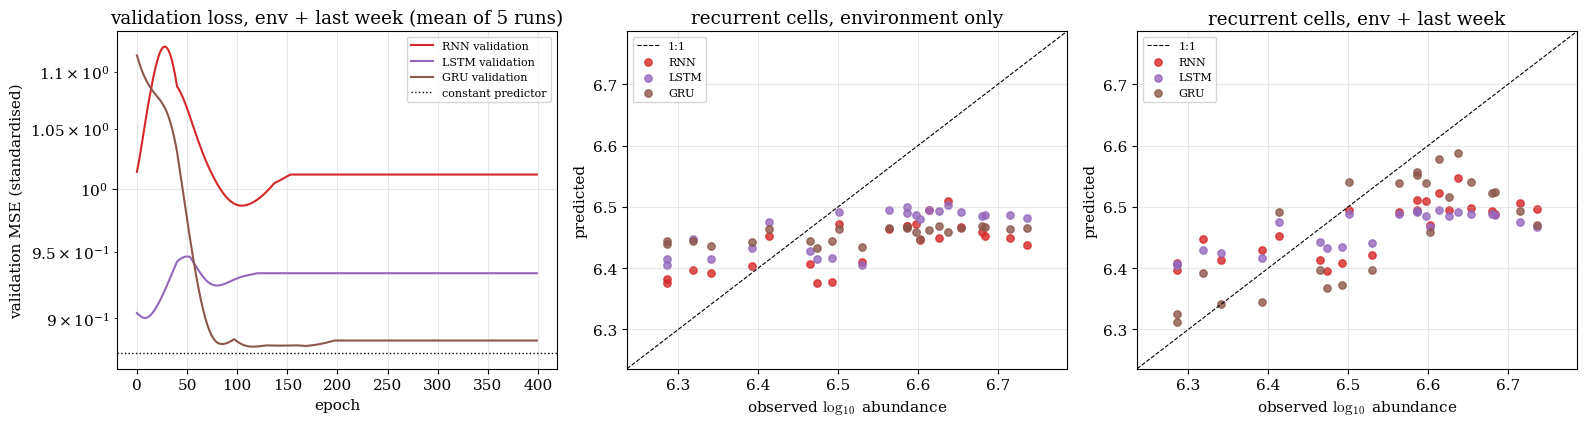

In [84]:
kinds = ["rnn", "lstm", "gru"]
colours = {"rnn": "tab:red", "lstm": "tab:purple", "gru": "tab:brown"}
D_ar = window_data(k_rnn, ar=True)
cur_rec = {kd: curves(lambda: Recurrent(D_ar["n_ch"], hidden=h_rnn, kind=kd), as_tuple(D_ar), SEEDS_CURVE) for kd in kinds}
names_ar = {kd: f"{kd.upper()} (env + last week, k {k_rnn}, h {h_rnn})" for kd in kinds}
names_env = {kd: f"{kd.upper()} (env only, k {k_rnn}, h {h_rnn})" for kd in kinds}
m_ar = {kd: pred_metrics(results[names_ar[kd]]["pred"]) for kd in kinds}
m_env = {kd: pred_metrics(results[names_env[kd]]["pred"]) for kd in kinds}
s_rec = {kd: lc_stats(cur_rec[kd]) for kd in kinds}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for kd in kinds:
    va = np.mean([np.interp(np.arange(400), np.arange(len(c[1])), c[1]) for c in cur_rec[kd]], axis=0)
    axes[0].plot(va, color=colours[kd], label=f"{kd.upper()} validation")
axes[0].axhline(const_val, color="k", ls=":", lw=1, label="constant predictor")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation MSE (standardised)")
axes[0].set_title("validation loss, env + last week (mean of 5 runs)"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
plot_scatter(axes[1], [(kd.upper(), results[names_env[kd]]["pred"], colours[kd]) for kd in kinds], "recurrent cells, environment only")
plot_scatter(axes[2], [(kd.upper(), results[names_ar[kd]]["pred"], colours[kd]) for kd in kinds], "recurrent cells, env + last week")
plt.tight_layout()

best_kd = min(m_ar, key=lambda kd: m_ar[kd]["rmse"])

**Figure 8.** Recurrent networks (window length 1, hidden size 8). Left: validation loss of the three cell types with the previous week's abundance as an input (mean of five initialisations; curves interpolated to 400 epochs). Middle and right: predicted against observed $\log_{10}$ abundance in the test period for the ensemble means, without and with the previous week's abundance.

With the previous week's abundance, the validation loss at the selected epoch is 0.88 (RNN, epoch 0), 0.85 (LSTM, epoch 13) and 0.80 (GRU, epoch 89), against 0.87 for the constant predictor. Using the environment only, the ensembles give (test period) RNN: $r = 0.71$, RMSE = 0.145 dex, slope = 2.40; LSTM: $r = 0.74$, RMSE = 0.130 dex, slope = 2.82; GRU: $r = 0.71$, RMSE = 0.147 dex, slope = 7.65. With the previous week's abundance they give RNN: $r = 0.78$, RMSE = 0.122 dex, slope = 2.32; LSTM: $r = 0.81$, RMSE = 0.130 dex, slope = 3.56; GRU: $r = 0.77$, RMSE = 0.110 dex, slope = 1.17. The GRU has the lowest RMSE for the lagged input (bias $-0.068$ dex, amplitude ratio 0.66). The mean change in RMSE from adding the previous week's abundance is $-0.020$ dex over the three cells (an improvement).
Only the GRU improves its validation loss appreciably relative to the constant predictor (0.80 against 0.87); the RNN and the LSTM stop at epochs 0 and 13, i.e. close to their initial state. Calibration slopes well above 1 for most models show that the predictions are damped; the GRU with the lagged input is the best calibrated (slope 1.17).

## 8.4 Supplementary experiment: do recurrent cells exploit memory in longer windows?

Because the validation search selected $k = 1$, Table 5 does not test memory. The three cell types are therefore retrained with the same hidden size on windows of 4 and 8 weeks (all other settings unchanged, eight initialisations each), with and without the previous week's abundance. If memory were useful, the ensemble test RMSE should decrease for $k > 1$ relative to $k = 1$. These runs are kept outside the model comparison of §9, so that this exploratory experiment cannot influence model selection.

In [88]:
mem_rows = []
for k in [k_rnn, 4, 8]:
    for ar in [False, True]:
        D = window_data(k, ar=ar)
        for kind in ["rnn", "lstm", "gru"]:
            pv, pt, _ = run_seeds(lambda: Recurrent(D["n_ch"], hidden=h_rnn, kind=kind), as_tuple(D), SEEDS_FINAL)
            per_run = [rmse_dex(yte_s, p) for p in pt]
            mem_rows.append(dict(k=k, input="env + last week" if ar else "env only", cell=kind.upper(),
                                 val=rmse_dex(yva_s, pv.mean(0)), test_single=np.mean(per_run),
                                 spread=np.std(per_run), test_ens=rmse_dex(yte_s, pt.mean(0))))
mem = pd.DataFrame(mem_rows)
print("ensemble test RMSE (dex) by window length k:")
display(mem.pivot_table(index=["input", "cell"], columns="k", values="test_ens").round(3))
print("single-run test RMSE (dex), mean over seeds, by window length k:")
display(mem.pivot_table(index=["input", "cell"], columns="k", values="test_single").round(3))

ensemble test RMSE (dex) by window length k:


k                         1      4      8
input           cell                     
env + last week GRU   0.110  0.147  0.153
                LSTM  0.130  0.156  0.156
                RNN   0.122  0.141  0.142
env only        GRU   0.147  0.161  0.162
                LSTM  0.130  0.155  0.155
                RNN   0.145  0.144  0.148

single-run test RMSE (dex), mean over seeds, by window length k:


k                         1      4      8
input           cell                     
env + last week GRU   0.121  0.156  0.162
                LSTM  0.139  0.159  0.159
                RNN   0.139  0.150  0.151
env only        GRU   0.156  0.169  0.171
                LSTM  0.145  0.157  0.157
                RNN   0.161  0.159  0.160

**Table 6.** Test RMSE (dex) of the ensemble (upper table) and of single runs (lower table, mean over seeds) of RNN, LSTM and GRU, by window length $k$ and input set (printed above).

Averaged over the three cell types, the ensemble test RMSE is 0.121 ($k = 1$), 0.148 ($k = 4$) and 0.151 dex ($k = 8$) with the previous week's abundance, and 0.141, 0.153 and 0.155 dex using the environment only. Longer windows therefore do not improve the result by more than 0.005 dex relative to $k = 1$; in all configurations except one (RNN, environment only, $k = 4$: 0.144 against 0.145 dex) they increase it. The lowest value in this experiment is 0.110 dex (GRU, $k = 1$, environment plus previous week; validation RMSE 0.136 dex). The spread between initialisations of a single configuration is typically 0.025 dex, so differences below about this size are not interpreted. The recurrent cells do not exploit longer environmental histories: increasing the window length from one to four or eight weeks raises the error, consistent with the CNN result (section 7) and with the larger number of inputs relative to ~100 training windows.

-----------------------
# 9. Comparison and conclusions

The autoencoder-plus-ridge model is first logged with the latent size selected by validation RMSE, so that it appears in the final comparison alongside the other models. All models are then ranked.

In [93]:
L_best = min(ae_preds, key=lambda L: rmse_dex(yva_s, ae_preds[L][0].mean(0)))
ae_name = f"AE (L={L_best}) + ridge"
record(ae_name, *ae_preds[L_best])
print(f"latent size chosen on validation: L = {L_best}")

baseline_names = ["Training mean", "Persistence", "Seasonal climatology", "Ridge (env only)", "Ridge (env + last week)"]
ablation_names = ["MLP best, inputs NOT standardised"]
window_ridge = [k for k in results if k.startswith("Ridge, ")]
nn_names = [k for k in results if k not in baseline_names + ablation_names + window_ridge]

tab = pd.DataFrame({k: {"val RMSE": v["val"], "test RMSE": v["test"],
                        "single-run test RMSE": f"{v['test_seed_mean']:.3f} +/- {v['test_seed_sd']:.3f}",
                        "skill": v["skill"], "skill 95% CI": f"[{v['ci'][0]:.2f}, {v['ci'][1]:.2f}]"}
                    for k, v in results.items()}).T
tab = tab.astype({"val RMSE": float, "test RMSE": float, "skill": float})
tab.sort_values("test RMSE").round(3)

latent size chosen on validation: L = 6


,val RMSE,test RMSE,single-run test RMSE,skill,skill 95% CI
"GRU (env + last week, k 1, h 8)",0.136,0.110,0.121 +/- 0.024,0.529,"[0.37, 0.70]"
"MLP 2 hidden layers (32, 16, ReLU)",0.107,0.117,0.127 +/- 0.015,0.465,"[0.17, 0.69]"
"MLP best (width 64, wd 0.001)",0.117,0.121,0.126 +/- 0.005,0.427,"[0.06, 0.69]"
Ridge (env + last week),0.150,0.122,0.122 +/- 0.000,0.425,"[0.23, 0.64]"
"Ridge, 1-week window (env + last week)",0.150,0.122,0.122 +/- 0.000,0.425,"[0.23, 0.64]"
"RNN (env + last week, k 1, h 8)",0.132,0.122,0.139 +/- 0.031,0.424,"[0.34, 0.51]"
"LSTM (env only, k 1, h 8)",0.130,0.130,0.145 +/- 0.017,0.347,"[0.27, 0.42]"
"LSTM (env + last week, k 1, h 8)",0.138,0.130,0.139 +/- 0.029,0.338,"[0.28, 0.41]"
MLP linear (no hidden layer),0.130,0.132,0.153 +/- 0.026,0.324,"[0.19, 0.46]"
"MLP 2 layers, no activation",0.134,0.132,0.148 +/- 0.020,0.322,"[0.19, 0.48]"


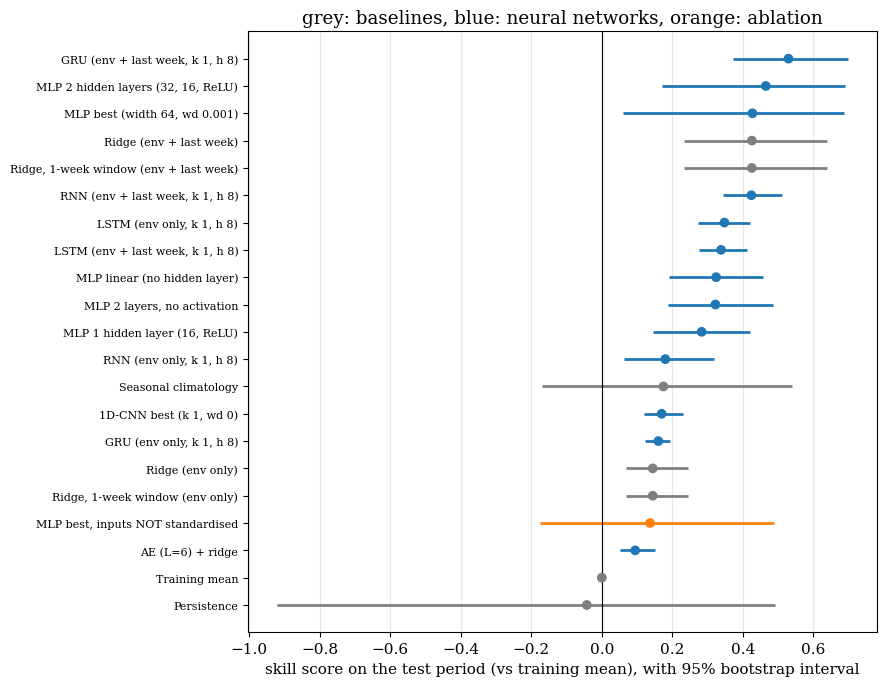

In [94]:
order = sorted(results, key=lambda k: results[k]["test"])
fig = plt.figure(figsize=(9, 7))
ax = plt.axes()
yy = np.arange(len(order))
sk = np.array([results[k]["skill"] for k in order])
lo = np.array([results[k]["ci"][0] for k in order])
hi = np.array([results[k]["ci"][1] for k in order])
colours = ["tab:grey" if k in baseline_names + window_ridge else ("tab:orange" if k in ablation_names else "tab:blue") for k in order]
ax.hlines(yy, lo, hi, color=colours, lw=2)
ax.scatter(sk, yy, c=colours, zorder=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(yy); ax.set_yticklabels(order, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("skill score on the test period (vs training mean), with 95% bootstrap interval")
ax.set_title("grey: baselines, blue: neural networks, orange: ablation")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()

**Table 7 and Figure 9.** Test-period RMSE, skill score relative to the training mean and 95% bootstrap interval for all 21 models (table above) and as a plot (grey: baselines; blue: neural networks; orange: unstandardised-input ablation). The latent size selected for the autoencoder is $L = 6$.

*Results (ranking).* By test RMSE of the ensemble, the best models are the GRU with the previous week's abundance (0.110 dex, skill 0.53, 95% CI 0.37 to 0.70), the (32, 16) MLP (0.117 dex, 0.47, CI 0.17 to 0.69), the width-64 MLP (0.121 dex, 0.43, CI 0.06 to 0.69), ridge with the previous week's abundance (0.122 dex, 0.43, CI 0.23 to 0.64) and the RNN with the previous week's abundance (0.122 dex, 0.42, CI 0.34 to 0.51). Persistence (skill $-0.04$), the seasonal climatology (0.18) and the unstandardised MLP (0.14) have intervals that include zero. Seventeen of the 21 models have an interval entirely above zero, but the intervals of the five best models overlap almost completely, so their ranking is not statistically supported.

*Results (mean shift).* The skill is measured against the training mean, but the mean of the test period (6.53) is 0.09 dex higher than that of the training period (6.44). A constant prediction equal to the test-period mean, which is not available in practice, would already have an RMSE of 0.133 dex (skill 0.31). Positive skill therefore does not by itself demonstrate predictive information beyond following the shift in the mean. Against this stricter reference, only models with an ensemble RMSE below 0.133 dex add information: the GRU (0.110), the (32, 16) MLP (0.117), the width-64 MLP (0.121), both ridge models with the lagged abundance and the RNN with the lagged abundance (0.122), the two LSTMs (0.130) and, marginally, the linear MLPs (0.132). The environment-only ridge (0.148), the CNN (0.146), the autoencoder model (0.153) and the seasonal climatology (0.146) do not. Relative to the constant reference, the best models reduce the mean squared error by about 23% (MLP, 0.117 dex) to 32% (GRU, 0.110 dex).

## 9.1 Statistical comparison of the selected models

The network with the lowest *validation* RMSE (not test RMSE, to avoid selecting the winner after seeing the test set) is compared with the best ridge variant (also selected on validation RMSE) using a paired bootstrap of the difference in mean squared error.

In [96]:
nn_best = min(nn_names, key=lambda k: results[k]["val"])
ridge_names = [k for k in results if k.startswith("Ridge")]
ridge_best = min(ridge_names, key=lambda k: results[k]["val"])     # best ridge variant, also chosen on validation
rn, rr = results[nn_best], results[ridge_best]
d_lo, d_hi = boot_mse_diff(yte_s, rn["pred"], rr["pred"])
verdict = ("a statistically distinguishable difference" if (d_lo > 0 or d_hi < 0) else "no difference distinguishable from noise")

print(f"network with lowest validation RMSE : {nn_best}")
print(f"  test RMSE {rn['test']:.3f} dex, skill {rn['skill']:.2f}, 95% CI [{rn['ci'][0]:.2f}, {rn['ci'][1]:.2f}]")
print(f"best ridge variant by validation RMSE : {ridge_best}")
print(f"  test RMSE {rr['test']:.3f} dex, skill {rr['skill']:.2f}, 95% CI [{rr['ci'][0]:.2f}, {rr['ci'][1]:.2f}]")
print(f"training mean test RMSE : {results['Training mean']['test']:.3f} dex")
print(f"paired bootstrap 95% interval of MSE(network) - MSE(ridge variant): [{d_lo:+.4f}, {d_hi:+.4f}] -> {verdict}")
print(f"lowest test RMSE of all models (descriptive only): {order[0]} at {results[order[0]]['test']:.3f} dex")

network with lowest validation RMSE : MLP 2 hidden layers (32, 16, ReLU)
  test RMSE 0.117 dex, skill 0.46, 95% CI [0.17, 0.69]
best ridge variant by validation RMSE : Ridge (env + last week)
  test RMSE 0.122 dex, skill 0.43, 95% CI [0.23, 0.64]
training mean test RMSE : 0.160 dex
paired bootstrap 95% interval of MSE(network) - MSE(ridge variant): [-0.2467, +0.1611] -> no difference distinguishable from noise
lowest test RMSE of all models (descriptive only): GRU (env + last week, k 1, h 8) at 0.110 dex




## 9.2 Predictions of one model per family

Test-period predictions of one model per family (MLP, CNN, autoencoder with ridge, best recurrent cell with the previous week's abundance) and of the environment-only ridge regression are compared with the observations.

,correlation,RMSE (dex),bias (dex),calibration slope,amplitude ratio
MLP,0.717,0.121,-0.063,0.675,1.061
1D-CNN,0.741,0.146,-0.086,4.710,0.157
AE + ridge,0.676,0.153,-0.087,7.464,0.091
GRU (env + last week),0.765,0.110,-0.068,1.167,0.655
Ridge (env only),0.655,0.148,-0.087,4.063,0.161


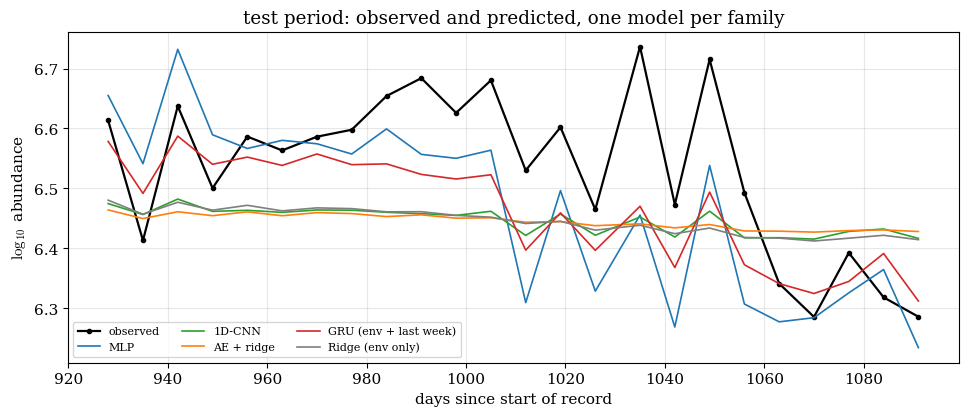

In [100]:
fam = {"MLP": mlp_name, "1D-CNN": cnn_name, "AE + ridge": ae_name, f"{best_kd.upper()} (env + last week)": names_ar[best_kd],
       "Ridge (env only)": "Ridge (env only)"}
fam_c = ["tab:blue", "tab:green", "tab:orange", "tab:red", "tab:grey"]
met = {k: pred_metrics(results[v]["pred"]) for k, v in fam.items()}

fig = plt.figure(figsize=(11.5, 4.3))
ax = plt.axes()
days = df["YearDay"].values[idx_te]
ax.plot(days, obs, "k.-", lw=1.6, label="observed")
for (k, v), c in zip(fam.items(), fam_c):
    ax.plot(days, to_dex(results[v]["pred"]), color=c, lw=1.2, label=k)
ax.set_xlabel("days since start of record"); ax.set_ylabel(r"$\log_{10}$ abundance")
ax.set_title("test period: observed and predicted, one model per family")
ax.legend(fontsize=8, ncol=3); ax.grid(alpha=0.3)

tab_fam = pd.DataFrame(met).T.rename(columns={"r": "correlation", "rmse": "RMSE (dex)", "bias": "bias (dex)",
                                                "slope": "calibration slope", "amp": "amplitude ratio"})
display(tab_fam.round(3))
order_f = tab_fam["RMSE (dex)"].sort_values().index.tolist()
res_med = {k: float(np.median(np.abs(to_dex(results[v]["pred"]) - obs))) for k, v in fam.items()}

**Figure 10 and Table 8.** Test-period predictions of one model of each family (MLP, CNN, autoencoder with ridge, best recurrent cell with the previous week's abundance) and of the environment-only ridge regression, with the corresponding diagnostics.

Ordered by RMSE, the models are GRU with lagged abundance (0.110 dex, $r = 0.77$), MLP (0.121 dex, $r = 0.72$), 1D-CNN (0.146 dex, $r = 0.74$), ridge on the environment (0.148 dex, $r = 0.66$) and AE + ridge (0.153 dex, $r = 0.68$). The median absolute errors are 0.071, 0.082, 0.126, 0.123 and 0.133 dex, respectively. The amplitude ratios are 0.66 (GRU), 1.06 (MLP), 0.16 (CNN), 0.16 (ridge) and 0.09 (AE + ridge). The model with the lowest RMSE (GRU) also has the highest correlation, so its advantage combines timing and amplitude. The CNN, ridge and AE + ridge predictions have amplitude ratios of only 0.09–0.16, i.e. they are nearly constant and lie systematically below the observations (bias about $-0.09$ dex), so their modest skill reflects mostly a small variation around the training mean. Only the MLP reproduces the amplitude of the observed variability (ratio 1.06), albeit with a calibration slope of 0.68 indicating partial phase error. The median absolute error, which is less affected by the few extreme weeks than the RMSE, is lowest for the GRU and the MLP, consistent with the RMSE ranking.

## 9.3 Conclusions


1. *What fraction of the variability of $\log_{10}$ abundance is predictable from the environment?* On the test period, the best environment-only model (the (32, 16) MLP) has an RMSE of 0.117 dex, compared with 0.160 dex for the training mean, 0.133 dex for an (unavailable) constant equal to the test mean and 0.148 dex for ridge on the same variables. This is a 23% reduction of the mean squared error relative to the constant reference. The 5-fold blocked cross-validation gives a consistent picture (RMSE 0.127 dex for the MLP, 0.140 dex for ridge and 0.163 dex for the mean; skill 0.39 and 0.26). The environment explains a modest but real part of the variability, of the order of one quarter to one third of the variance; most of the week-to-week scatter remains unexplained.
2. *Does nonlinearity help, and what is the effect of omitting standardisation and early stopping?* Nonlinearity helps for sufficiently large networks: a (32, 16) network, or a one-layer network with at least 32 units, reduces the error relative to the linear model (0.127 ± 0.015 dex against 0.153 ± 0.026 dex for single runs; 9% lower RMSE than ridge in cross-validation, better in four of five blocks), whereas small networks with 16 or fewer units are no better than the linear one. Input standardisation is essential (test RMSE 0.312 ± 0.265 dex without it). Early stopping, in contrast, made no measurable difference for the width-64 network (0.126 against 0.129 dex), which interpolates the training set (loss $\sim10^{-10}$) without an increase of its validation error.
3. *Is the redundancy of the environmental variables sufficient for a compressed representation?* Only linearly and only moderately. Four principal components leave a test-period reconstruction error of 0.26 (about three quarters of the variance retained) and give the same ridge RMSE as all twelve variables (0.148 dex). The nonlinear autoencoder reconstructs worse than PCA at four of five latent sizes and its codes give a worse regression; it is not preferable for this sample size.
4. *Does temporal context help?* The environmental history does not: for the CNN and the LSTM the best window was one week, and longer windows had equal or larger validation error (Table 4, Figure 7). In the supplementary experiment (Table 6), the recurrent cells likewise performed worse with windows of 4 and 8 weeks (ensemble RMSE 0.148 and 0.151 dex with, 0.153 and 0.155 dex without lagged abundance, against 0.121 and 0.141 dex at $k = 1$). The *previous week's abundance*, however, helps substantially in combination with the environment: ridge improved from 0.148 to 0.122 dex and the GRU from 0.156 to 0.121 dex (single runs), although persistence alone has no skill.

**Model comparison.** The network selected on validation (the (32, 16) MLP, 0.117 dex) and the best ridge model with an additional input (0.122 dex) cannot be distinguished (the paired bootstrap interval of the difference in squared error includes zero). The nominally best model, the GRU with the previous week's abundance (0.110 dex, skill 0.53), was identified from the test set and is therefore only descriptive. The most informative comparison is that a nonlinear MLP using *only the environment* matches a linear model that is additionally given the previous week's abundance: the nonlinear model extracts from the environment what the linear model requires the lag for.


**Limitations.**

1. Only 151 samples are available, with 22 and 24 evaluation weeks, so differences of the order of 0.01 dex are within the noise.
2. The validation and test periods cover different parts of the year, so that the evaluation confounds unseen time with unseen season; in addition, the test mean is shifted relative to the training mean (hence the comparison with the constant reference).
3. Hyper-parameter searches were small and used three initialisations per cell; for the MLP the best width lies at the edge of the grid, and the isolated optimum of the LSTM search (Figure 7) illustrates how readily such a search is driven by chance.
4. The validation RMSE of early-stopped networks is optimistic because the validation set selects the stopping epoch; model selection used validation results only, and the ranking by test RMSE is descriptive.
5. The irregular sampling gaps (up to 21 days) were ignored in forming windows.
6. The bootstrap treats weeks as independent and therefore slightly understates the uncertainty.
7. Tree-based models and Gaussian processes, which are often competitive for small tabular data sets, were not evaluated.




# 10. References

1. Azam, F., Fenchel, T., Field, J. G., Gray, J. S., Meyer-Reil, L. A. and Thingstad, F. (1983). The ecological role of water-column microbes in the sea. *Marine Ecology Progress Series*, 10, 257–263. https://doi.org/10.3354/meps010257

2. Bergmeir, C. and Benítez, J. M. (2012). On the use of cross-validation for time series predictor evaluation. *Information Sciences*, 191, 192–213. https://doi.org/10.1016/j.ins.2011.12.028

3. Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H. and Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. In *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing (EMNLP)*, 1724–1734. https://doi.org/10.3115/v1/D14-1179

4. Cole, J. J., Findlay, S. and Pace, M. L. (1988). Bacterial production in fresh and saltwater ecosystems: a cross-system overview. *Marine Ecology Progress Series*, 43, 1–10. https://doi.org/10.3354/meps043001

5. Hinton, G. E. and Salakhutdinov, R. R. (2006). Reducing the dimensionality of data with neural networks. *Science*, 313(5786), 504–507. https://doi.org/10.1126/science.1127647

6. Hochreiter, S. and Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780. https://doi.org/10.1162/neco.1997.9.8.1735

7. Hyndman, R. J. and Athanasopoulos, G. (2021). *Forecasting: Principles and Practice*, 3rd edition. OTexts, Melbourne. https://otexts.com/fpp3/

8. Kingma, D. P. and Ba, J. (2015). Adam: a method for stochastic optimization. In *3rd International Conference on Learning Representations (ICLR 2015)*. arXiv:1412.6980.

9. Paszke, A., Gross, S., Massa, F., Lerer, A., Bradbury, J., Chanan, G., et al. (2019). PyTorch: an imperative style, high-performance deep learning library. In *Advances in Neural Information Processing Systems 32*, 8024–8035. arXiv:1912.01703.

10. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., et al. (2011). Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.


